# **Where Is the Money Lost? Exploratory Analysis of Credit Card Fraud on 34.6M Transactions**

# **Part 1 - Business Problem**

Credit card fraud causes direct financial losses through chargebacks and reimbursements, increases operational costs from manual reviews and disputes, and erodes customer trust. Fraud is rare and constantly evolving: in this dataset, only about 0.55% of 34.6 million transactions (January 2019 to December 2020) are fraudulent. Because the share is so small, fraud is easy to overlook in aggregate numbers, and rules or manual reviews applied to every transaction do not scale.

Before building any detection model, the business needs to understand **where the fraud loss is concentrated and which behaviors set fraudulent transactions apart**. Without that, review teams spread their effort evenly, blocking rules are guesses, and a model would be built on assumptions instead of evidence.

**Objective:** run an exploratory data analysis on the full dataset to locate the fraud loss, measure the risk across categories, amounts, hours, locations and customer profiles, and identify the signals worth carrying into the predictive models (Machine Learning and Neural Network notebooks).

**Business questions:**

1. How much of the financial volume is fraud, by count and by amount?
2. Does the fraud loss grow or oscillate over time?
3. Which purchase categories concentrate the most loss, and which carry the highest risk?
4. Which purchase amount bands have the highest fraud rate?
5. At what hours of the day does fraud happen?
6. Is there a weekday and hour combination that is especially dangerous?
7. Does fraud happen far from where the customer lives?
8. Which states concentrate the loss?
9. Which customer profiles (age and gender) are most affected?
10. Is the loss concentrated in a few merchants or spread out?
11. Which variables move together, and which move with fraud?

**How the findings will be read:**

- **Share versus risk:** where the money is lost (total amount) is different from where fraud is most likely (rate). Every comparison separates the two.
- **Sample size:** every rate is shown with its number of transactions, so a high rate on a tiny group is not mistaken for a finding.
- **Association, not cause:** the analysis shows patterns in the data, not the reason behind them.

**Expected business impact:** a clear map of where to focus fraud reviews and blocking rules, and a short list of evidence-based features to feed the predictive models.

In [1]:
# Importação das bibliotecas
import os
from pathlib import Path
import shutil
import shutil
import subprocess

import polars as pl
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

COR_PRIMARIA = "#0072B2"    # main series / série principal
COR_SECUNDARIA = "#94A3B8"  # neutral support / apoio neutro
COR_DESTAQUE = "#E69F00"    # key highlight / destaque principal
PALETA = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"]

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 110,
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.prop_cycle": plt.cycler(color=PALETA),
})

# **Part 2 - Local paths**

In [2]:
"""Local folders, relative to the repository root.

Pastas locais, relativas à raiz do repositório.
"""

# works whether Jupyter starts in notebook/ or in the repository root / funciona se o Jupyter abrir em notebook/ ou na raiz
RAIZ = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()

DATA_DIR = RAIZ / "input"  # raw dataset and Parquet / base bruta e Parquet

CSV_PATH = str(DATA_DIR / "credit_card_fraud.csv")
PARQUET_PATH = str(DATA_DIR / "credit_card_fraud_full.parquet")

DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Root / Raiz:", RAIZ)
print(f"Free disk / Espaço livre: {shutil.disk_usage(RAIZ).free / 1e9:.1f} GB")

Root / Raiz: c:\Users\rafae\Documents\Projetos_data_science_IA\machine_learning\Credit-Card-Fraud-Detection-on-34.6M-Transactions
Free disk / Espaço livre: 651.8 GB


# **Part 3 - Database**

In [3]:
"""Confirm the dataset is in input/ (no download needed locally).

Confirma que a base está em input/ (não precisa baixar localmente).
"""

csv_path = CSV_PATH
if not os.path.exists(csv_path):
    raise FileNotFoundError(f"Put credit_card_fraud.csv in / Coloque credit_card_fraud.csv em {DATA_DIR}")
print(f"File size / Tamanho do arquivo: {os.path.getsize(csv_path) / 1e9:.2f} GB")

File size / Tamanho do arquivo: 11.19 GB


# **Part 4 - Pré-processamento**

In [4]:
"""Check column names and types from the first rows of the CSV.

Checa nomes e tipos das colunas nas primeiras linhas do CSV.
"""

# read only 1000 rows, instant even on an 11 GB file / ler só 1000 linhas, instantâneo mesmo em arquivo de 11 GB
amostra = pl.read_csv(CSV_PATH, n_rows=1000)
print(amostra.shape)
print(amostra.schema)

(1000, 27)
Schema({'': Int64, 'ssn': String, 'cc_num': Int64, 'first': String, 'last': String, 'gender': String, 'street': String, 'city': String, 'state': String, 'zip': Int64, 'lat': Float64, 'long': Float64, 'city_pop': Int64, 'job': String, 'dob': String, 'acct_num': Int64, 'profile': String, 'trans_num': String, 'trans_date': String, 'trans_time': String, 'unix_time': Int64, 'category': String, 'amt': Float64, 'is_fraud': Int64, 'merchant': String, 'merch_lat': Float64, 'merch_long': Float64})


In [5]:
# columns the conversion expects / colunas que a conversão espera
keep_cols = [
    "unix_time", "dob", "lat", "long", "merch_lat", "merch_long", "city_pop",
    "amt", "category", "gender", "state", "job", "merchant", "is_fraud",
]
print("Missing columns / Colunas ausentes:", [c for c in keep_cols if c not in amostra.columns])

Missing columns / Colunas ausentes: []


In [6]:
"""Convert the full CSV to Parquet keeping only analysis columns.

Converte o CSV completo para Parquet mantendo só as colunas de análise.
"""

# input and output paths / caminhos de entrada e saída
csv_path = CSV_PATH
parquet_path = PARQUET_PATH

# columns kept, personal identifiers are dropped / colunas mantidas, identificadores pessoais removidos
keep_cols = [
    "unix_time", "dob", "lat", "long", "merch_lat", "merch_long", "city_pop",
    "amt", "category", "gender", "state", "job", "merchant", "is_fraud",
]

# lazy scan, fraud flag as boolean and timestamp from unix_time / leitura lazy, flag de fraude como booleano e timestamp a partir do unix_time
(
    pl.scan_csv(csv_path, infer_schema_length=10000)
    .select(keep_cols)
    .with_columns(
        pl.col("is_fraud").cast(pl.Boolean),
        pl.from_epoch("unix_time", time_unit="s").alias("trans_dt"),
    )
    .sink_parquet(parquet_path)
)
print(f"Parquet size: {os.path.getsize(parquet_path) / 1e9:.2f} GB")

Parquet size: 0.95 GB


In [7]:
"""Check shape, dtypes and a sample of the Parquet file.

Checa tamanho, tipos e uma amostra do arquivo Parquet.
"""

import polars as pl

pl.Config.set_tbl_cols(-1)

# lazy handle on the Parquet file / ponteiro lazy para o arquivo Parquet
lazy = pl.scan_parquet(PARQUET_PATH)

# row count and column types / contagem de linhas e tipos das colunas
print("Rows / Linhas:", lazy.select(pl.len()).collect().item())
print(lazy.collect_schema())

# small sample to confirm readable values / amostra pequena para confirmar valores legíveis
lazy.head(10).collect()

Rows / Linhas: 34636378
Schema({'unix_time': Int64, 'dob': String, 'lat': Float64, 'long': Float64, 'merch_lat': Float64, 'merch_long': Float64, 'city_pop': Int64, 'amt': Float64, 'category': String, 'gender': String, 'state': String, 'job': String, 'merchant': String, 'is_fraud': Boolean, 'trans_dt': Datetime(time_unit='us', time_zone=None)})


unix_time,dob,lat,long,merch_lat,merch_long,city_pop,amt,category,gender,state,job,merchant,is_fraud,trans_dt
i64,str,f64,f64,f64,f64,i64,f64,str,str,str,str,str,bool,datetime[μs]
1581715097,"""2003-09-14""",37.7383,-121.4345,38.724545,-120.916415,106426,4.34,"""misc_net""","""F""","""CA""","""Teaching laboratory technician""","""fraud_Moore, Dibbert and Koepp""",true,2020-02-14 21:18:17
1581710376,"""2003-09-14""",37.7383,-121.4345,37.288981,-121.791754,106426,11.2,"""misc_net""","""F""","""CA""","""Teaching laboratory technician""","""fraud_Dach-Nader""",true,2020-02-14 19:59:36
1581747004,"""2003-09-14""",37.7383,-121.4345,38.46153,-120.624583,106426,282.55,"""grocery_pos""","""F""","""CA""","""Teaching laboratory technician""","""fraud_Pacocha-O'Reilly""",true,2020-02-15 06:10:04
1581709848,"""2003-09-14""",37.7383,-121.4345,37.920539,-121.43939,106426,294.94,"""gas_transport""","""F""","""CA""","""Teaching laboratory technician""","""fraud_Kutch, Hermiston and Far…",true,2020-02-14 19:50:48
1581709519,"""2003-09-14""",37.7383,-121.4345,38.12385,-120.843755,106426,326.4,"""misc_net""","""F""","""CA""","""Teaching laboratory technician""","""fraud_Kuphal-Bartoletti""",true,2020-02-14 19:45:19
1581727053,"""2003-09-14""",37.7383,-121.4345,37.10285,-121.515057,106426,675.0,"""grocery_pos""","""F""","""CA""","""Teaching laboratory technician""","""fraud_Auer-Mosciski""",true,2020-02-15 00:37:33
1581712611,"""2003-09-14""",37.7383,-121.4345,37.819908,-121.793001,106426,628.75,"""grocery_pos""","""F""","""CA""","""Teaching laboratory technician""","""fraud_Strosin-Cruickshank""",true,2020-02-14 20:36:51
1581718745,"""2003-09-14""",37.7383,-121.4345,37.034358,-121.629142,106426,751.03,"""grocery_net""","""F""","""CA""","""Teaching laboratory technician""","""fraud_Towne, Walker and Borer""",true,2020-02-14 22:19:05
1581872880,"""2003-09-14""",37.7383,-121.4345,37.958785,-121.960836,106426,994.33,"""shopping_net""","""F""","""CA""","""Teaching laboratory technician""","""fraud_Volkman-Predovic""",true,2020-02-16 17:08:00


# **Part 5 - Limpeza de dados**

In [8]:
"""Count null values per column in the full Parquet file.

Conta valores nulos por coluna no arquivo Parquet completo.
"""

pl.Config.set_tbl_rows(30)

# fresh handle on the raw Parquet, independent of earlier filters / ponteiro novo para o Parquet bruto, independente de filtros anteriores
base_bruta = pl.scan_parquet(PARQUET_PATH)
n_total = base_bruta.select(pl.len()).collect().item()

# one row per column with null count and percentage / uma linha por coluna com contagem e porcentagem de nulos
nulos = (
    base_bruta.select(pl.all().null_count())
    .collect()
    .transpose(include_header=True, header_name="coluna", column_names=["nulos"])
    .with_columns((pl.col("nulos") / n_total * 100).round(4).alias("pct_nulos"))
)
print("Rows / Linhas:", n_total)
nulos

Rows / Linhas: 34636378


coluna,nulos,pct_nulos
str,u32,f64
"""unix_time""",0,0.0
"""dob""",0,0.0
"""lat""",0,0.0
"""long""",0,0.0
"""merch_lat""",0,0.0
"""merch_long""",0,0.0
"""city_pop""",0,0.0
"""amt""",0,0.0
"""category""",0,0.0


In [9]:
"""Count empty or blank text values in string columns.

Conta valores de texto vazios ou só com espaços nas colunas de texto.
"""

# blank means no content after removing spaces / vazio significa sem conteúdo após remover os espaços
base_bruta.select((pl.col(pl.String).str.strip_chars() == "").sum()).collect()

dob,category,gender,state,job,merchant
u32,u32,u32,u32,u32,u32
0,0,0,0,0,0


In [10]:
"""Check whether any transaction id appears more than once.

Checa se algum id de transação aparece mais de uma vez.
"""

# hash to 64 bits keeps memory low, collisions are practically impossible / hash de 64 bits economiza memória, colisões são praticamente impossíveis
ids = (
    pl.scan_csv(CSV_PATH, infer_schema_length=10000)
    .select(pl.col("trans_num").hash(seed=0).alias("h"))
)

# rows versus distinct ids / linhas versus ids distintos
ids.select(
    pl.len().alias("linhas"),
    pl.col("h").n_unique().alias("ids_unicos"),
).with_columns((pl.col("linhas") - pl.col("ids_unicos")).alias("repetidas")).collect()

linhas,ids_unicos,repetidas
u32,u32,u32
34636378,34636378,0


In [11]:
"""List distinct values of gender and category with their counts.

Lista os valores distintos de gênero e categoria com suas contagens.
"""

rotulos = pl.concat([
    base_bruta.group_by("gender").agg(pl.len().alias("n"))
    .select(pl.lit("gender").alias("coluna"), pl.col("gender").alias("valor"), "n"),
    base_bruta.group_by("category").agg(pl.len().alias("n"))
    .select(pl.lit("category").alias("coluna"), pl.col("category").alias("valor"), "n"),
]).sort(["coluna", "n"], descending=[False, True]).collect()
rotulos

coluna,valor,n
str,str,u32
"""category""","""shopping_pos""",3418709
"""category""","""grocery_pos""",3266890
"""category""","""home""",3253637
"""category""","""kids_pets""",3014244
"""category""","""gas_transport""",2980489
"""category""","""food_dining""",2602138
"""category""","""shopping_net""",2543488
"""category""","""entertainment""",2517230
"""category""","""personal_care""",2447892


In [12]:
"""Count distinct values of the text columns.

Conta valores distintos das colunas de texto.
"""

base_bruta.select(
    pl.col("state").n_unique().alias("estados"),
    pl.col("merchant").n_unique().alias("comerciantes"),
    pl.col("job").n_unique().alias("cargos"),
).collect()

estados,comerciantes,cargos
u32,u32,u32
51,693,639


# **Part 6 - Análise exploratoria de dados**

In [13]:
# one pass over the Parquet, only needed columns are read / uma passada no Parquet, só as colunas necessárias são lidas
resumo = lazy.select(
    pl.len().alias("n_transacoes"),
    pl.col("is_fraud").sum().alias("n_fraudes"),
    pl.col("amt").sum().alias("valor_total"),
    pl.col("amt").filter(pl.col("is_fraud")).sum().alias("valor_fraude"),
).collect()
resumo

n_transacoes,n_fraudes,valor_total,valor_fraude
u32,u32,f64,f64
34636378,189925,2.4618e9,1.0217e8


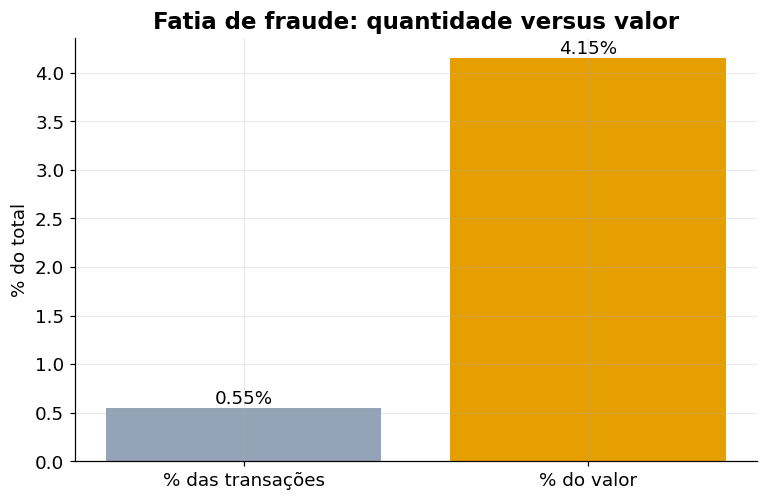

In [14]:
"""Fraud share by count versus by amount.

Fatia de fraude por quantidade versus por valor.
"""

r = resumo.row(0, named=True)
pct_qtd = r["n_fraudes"] / r["n_transacoes"] * 100
pct_valor = r["valor_fraude"] / r["valor_total"] * 100

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(["% das transações", "% do valor"], [pct_qtd, pct_valor], color=[COR_SECUNDARIA, COR_DESTAQUE])
ax.bar_label(ax.containers[0], fmt="%.2f%%")
ax.set_title("Fatia de fraude: quantidade versus valor")
ax.set_ylabel("% do total")
plt.show()

In [15]:
"""Build a uniform sample with numeric features for the correlation matrix.
Cria uma amostra uniforme com variáveis numéricas para a matriz de correlação.
"""

# haversine distance in km / distância haversine em km
lat1, lon1 = pl.col("lat").radians(), pl.col("long").radians()
lat2, lon2 = pl.col("merch_lat").radians(), pl.col("merch_long").radians()
a = ((lat2 - lat1) / 2).sin() ** 2 + lat1.cos() * lat2.cos() * ((lon2 - lon1) / 2).sin() ** 2

# every 30th row gives about 1.1M rows and keeps the real fraud rate / uma a cada 30 linhas dá cerca de 1,1M linhas e mantém a taxa real de fraude
amostra = (
    lazy.with_row_index("idx")
    .filter(pl.col("idx") % 30 == 0)
    .select(
        pl.col("amt").alias("valor"),
        pl.col("city_pop").alias("pop_cidade"),
        pl.col("lat").alias("lat_cliente"),
        pl.col("long").alias("long_cliente"),
        pl.col("merch_lat").alias("lat_comerc"),
        pl.col("merch_long").alias("long_comerc"),
        (6371 * 2 * a.sqrt().arcsin()).alias("distancia_km"),
        ((pl.col("trans_dt").dt.date() - pl.col("dob").str.to_date()).dt.total_days() / 365.25).alias("idade"),
        pl.col("trans_dt").dt.hour().alias("hora"),
        pl.col("trans_dt").dt.weekday().alias("dia_semana"),
        pl.col("trans_dt").dt.month().alias("mes"),
        pl.col("is_fraud").cast(pl.Int8).alias("fraude"),
    )
    .collect()
    .to_pandas()
)
print(amostra.shape, "| fraud rate / taxa de fraude:", round(amostra["fraude"].mean() * 100, 3), "%")
amostra.head()

(1154546, 12) | fraud rate / taxa de fraude: 0.538 %


,valor,pop_cidade,lat_cliente,long_cliente,lat_comerc,long_comerc,distancia_km,idade,hora,dia_semana,mes,fraude
0,4.34,106426,37.7383,-121.4345,38.724545,-120.916415,118.634486,16.418891,21,5,2,1
1,333.56,54963,32.9346,-96.5544,32.319614,-95.615212,111.408347,21.286790,21,5,10,1
2,46.99,54963,32.9346,-96.5544,32.569317,-96.142178,55.998829,19.912389,0,7,5,0
3,71.65,54963,32.9346,-96.5544,32.439038,-96.843991,61.407907,19.731691,21,4,3,0
4,62.82,54963,32.9346,-96.5544,32.883135,-96.451553,11.177101,19.663244,6,7,2,0


In [16]:
"""Spearman correlation matrix, robust to the skewed amount column.

Matriz de correlação de Spearman, robusta à assimetria da coluna de valor.
"""

# spearman uses ranks, so outliers in amount do not dominate / spearman usa ranks, então outliers no valor não dominam
corr = amostra.corr(method="spearman")
corr["fraude"].drop("fraude").sort_values(key=abs, ascending=False).to_frame("corr_com_fraude")

,corr_com_fraude
valor,0.084708
hora,0.065322
idade,0.017909
mes,-0.014031
dia_semana,-0.012230
long_comerc,0.001416
long_cliente,0.001291
pop_cidade,0.001141
lat_cliente,0.000374
lat_comerc,0.000336


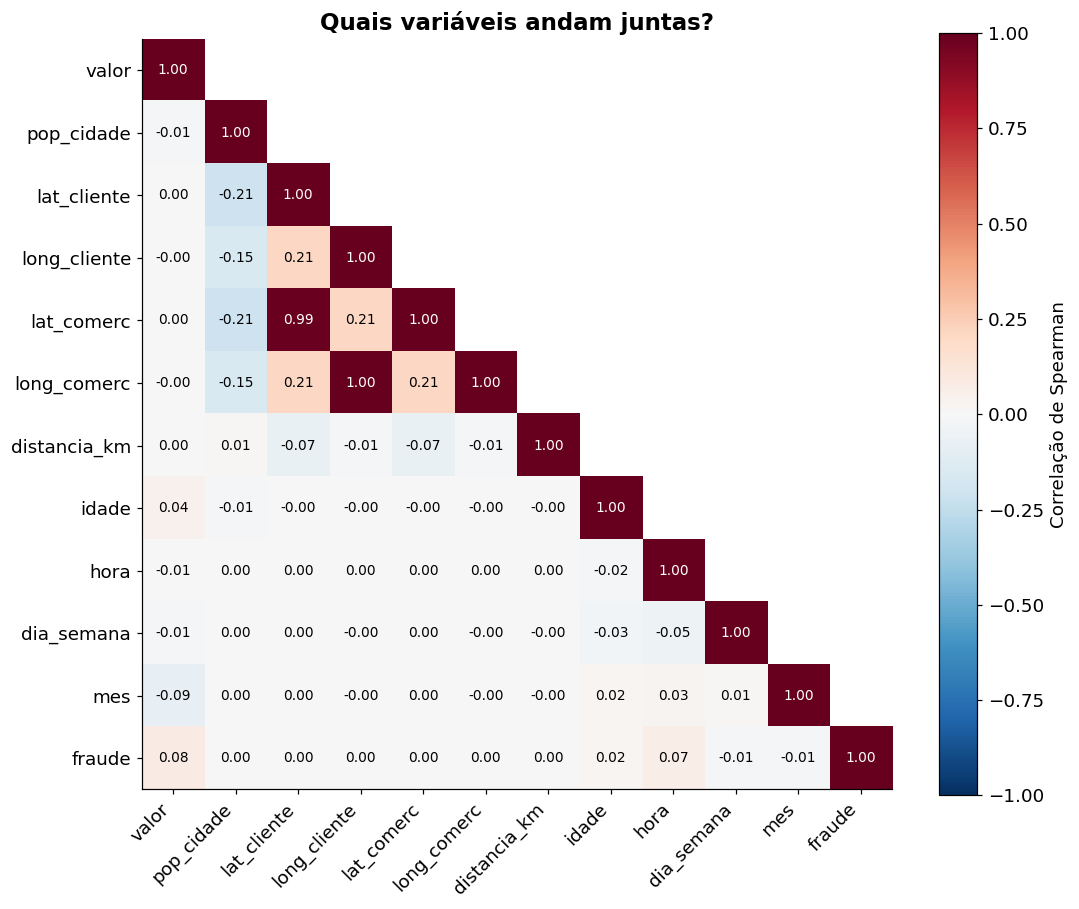

In [17]:
"""Lower-triangle heatmap of the correlation matrix.

Mapa de calor do triângulo inferior da matriz de correlação.
"""

# hide the upper triangle, it repeats the lower one / esconder o triângulo superior, que repete o inferior
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)
valores = np.ma.array(corr.values, mask=mascara)

fig, ax = plt.subplots(figsize=(11, 9))
img = ax.imshow(valores, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
ax.grid(False)

# print the coefficient inside each visible square / escrever o coeficiente dentro de cada quadrado visível
for i in range(len(corr)):
    for j in range(i + 1):
        cor_texto = "white" if abs(corr.iloc[i, j]) > 0.6 else "black"
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9, color=cor_texto)

fig.colorbar(img, ax=ax, label="Correlação de Spearman")
ax.set_title("Quais variáveis andam juntas?")
plt.show()

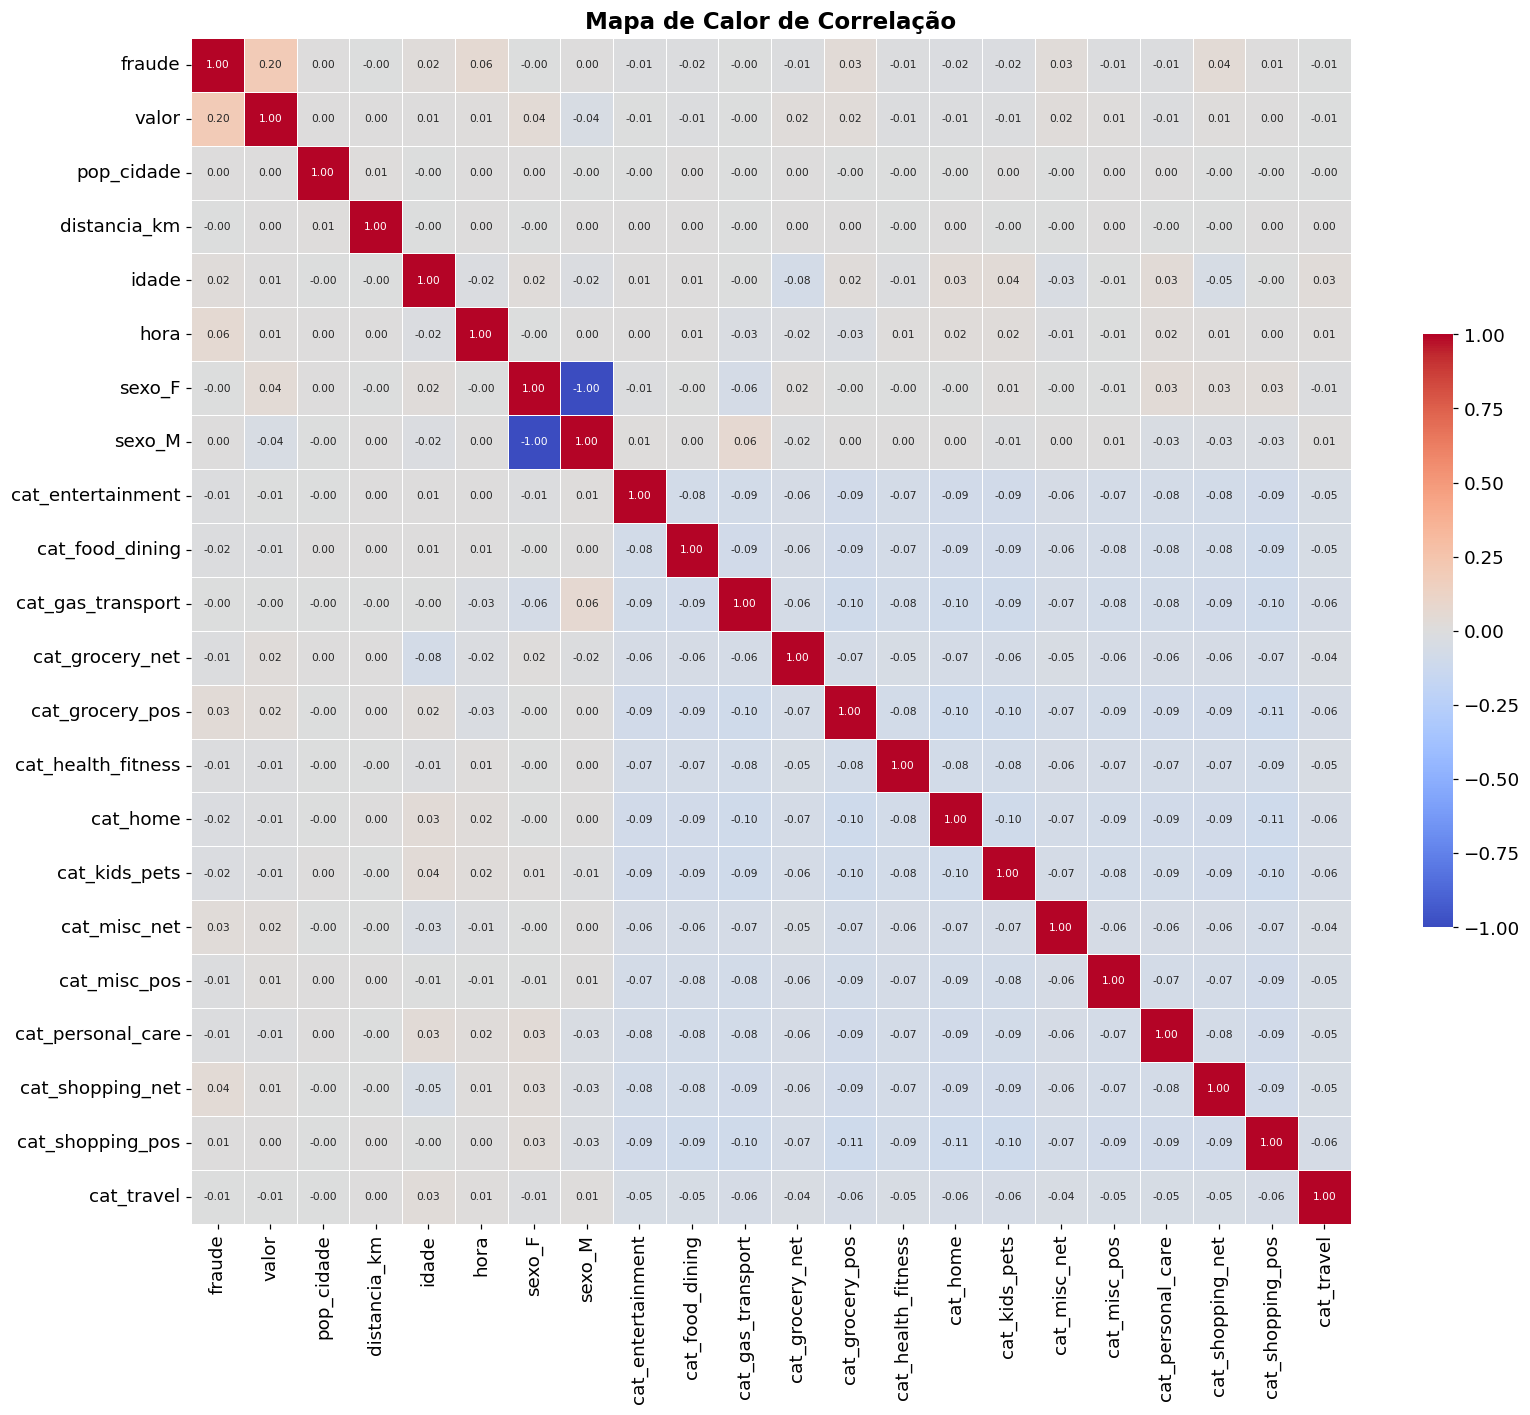

In [18]:
"""Seaborn correlation heatmap with gender and purchase categories as dummies.

Mapa de calor de correlação em seaborn com gênero e categorias de compra em colunas de sim/não.
"""

# haversine distance in km / distância haversine em km
lat1, lon1 = pl.col("lat").radians(), pl.col("long").radians()
lat2, lon2 = pl.col("merch_lat").radians(), pl.col("merch_long").radians()
a = ((lat2 - lat1) / 2).sin() ** 2 + lat1.cos() * lat2.cos() * ((lon2 - lon1) / 2).sin() ** 2

# every 30th row keeps the real fraud rate, about 1.1M rows / uma a cada 30 linhas mantém a taxa real de fraude, cerca de 1,1M linhas
base = (
    lazy.with_row_index("idx")
    .filter(pl.col("idx") % 30 == 0)
    .select(
        pl.col("amt").alias("valor"),
        pl.col("city_pop").alias("pop_cidade"),
        (6371 * 2 * a.sqrt().arcsin()).alias("distancia_km"),
        ((pl.col("trans_dt").dt.date() - pl.col("dob").str.to_date()).dt.total_days() / 365.25).alias("idade"),
        pl.col("trans_dt").dt.hour().alias("hora"),
        pl.col("gender").alias("sexo"),
        pl.col("category").alias("cat"),
        pl.col("is_fraud").cast(pl.Int8).alias("fraude"),
    )
    .collect()
    .to_pandas()
)

# one column per gender and per category / uma coluna por gênero e por categoria
dados = pd.get_dummies(base, columns=["sexo", "cat"], dtype=int)

# fraud first, then the other columns / fraude primeiro, depois as demais colunas
colunas = ["fraude"] + [c for c in dados.columns if c != "fraude"]
corr = dados[colunas].corr()

# palette name, try: coolwarm, RdBu_r, vlag, Spectral_r, PiYG / nome da paleta, teste: coolwarm, RdBu_r, vlag, Spectral_r, PiYG
PALETA_MAPA = "coolwarm"

fig, ax = plt.subplots(figsize=(17, 14))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap=PALETA_MAPA,
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 7},
    cbar_kws={"shrink": 0.5},
    ax=ax,
)
ax.grid(False)
ax.set_title("Mapa de Calor de Correlação")
plt.show()

In [19]:
"""Sample with numeric features and one-hot purchase categories.

Amostra com variáveis numéricas e categorias de compra em colunas de sim/não.
"""

# haversine distance in km / distância haversine em km
lat1, lon1 = pl.col("lat").radians(), pl.col("long").radians()
lat2, lon2 = pl.col("merch_lat").radians(), pl.col("merch_long").radians()
a = ((lat2 - lat1) / 2).sin() ** 2 + lat1.cos() * lat2.cos() * ((lon2 - lon1) / 2).sin() ** 2

# every 30th row keeps the real fraud rate / uma a cada 30 linhas mantém a taxa real de fraude
base = (
    lazy.with_row_index("idx")
    .filter(pl.col("idx") % 30 == 0)
    .select(
        pl.col("amt").log1p().alias("valor_log"),
        pl.col("city_pop").log1p().alias("pop_cidade_log"),
        (6371 * 2 * a.sqrt().arcsin()).alias("distancia_km"),
        ((pl.col("trans_dt").dt.date() - pl.col("dob").str.to_date()).dt.total_days() / 365.25).alias("idade"),
        pl.col("trans_dt").dt.hour().alias("hora"),
        pl.col("trans_dt").dt.hour().is_in([22, 23, 0, 1, 2, 3]).cast(pl.Int8).alias("noite_22h_3h"),
        (pl.col("gender") == "M").cast(pl.Int8).alias("genero_M"),
        pl.col("category"),
        pl.col("is_fraud").cast(pl.Int8).alias("fraude"),
    )
    .collect()
    .to_pandas()
)

# one column per category, 1 if the purchase is in it / uma coluna por categoria, 1 se a compra é dela
amostra2 = pd.get_dummies(base, columns=["category"], prefix="cat", dtype=int)
print(amostra2.shape, "| fraud rate / taxa de fraude:", round(amostra2["fraude"].mean() * 100, 3), "%")
amostra2.head()

(1154546, 22) | fraud rate / taxa de fraude: 0.538 %


,valor_log,pop_cidade_log,distancia_km,idade,hora,noite_22h_3h,genero_M,fraude,cat_entertainment,cat_food_dining,...,cat_grocery_pos,cat_health_fitness,cat_home,cat_kids_pets,cat_misc_net,cat_misc_pos,cat_personal_care,cat_shopping_net,cat_shopping_pos,cat_travel
0,1.675226,11.575215,118.634486,16.418891,21,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,0
1,5.812816,10.914434,111.408347,21.286790,21,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3.870993,10.914434,55.998829,19.912389,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4.285653,10.914434,61.407907,19.731691,21,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4.156067,10.914434,11.177101,19.663244,6,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


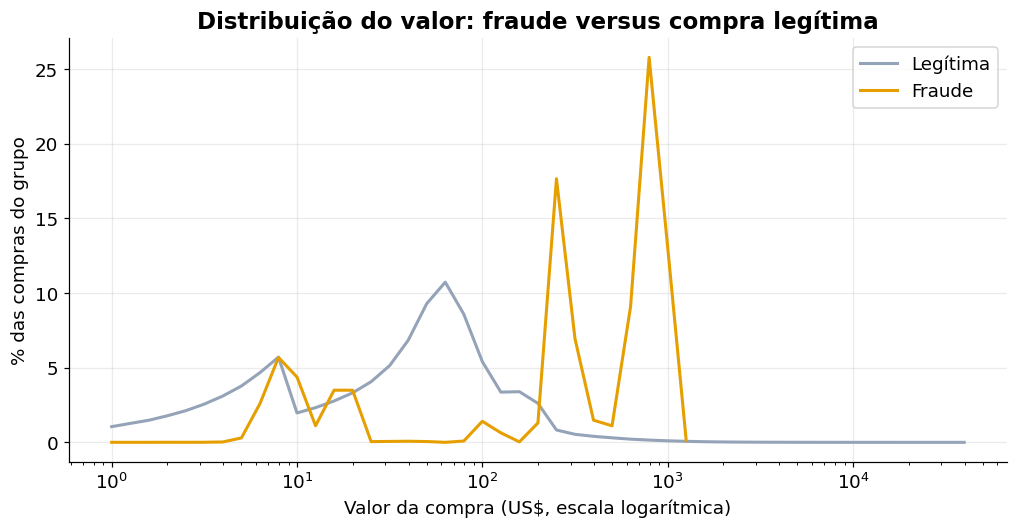

In [20]:
"""Share of purchases by amount on a log scale, fraud versus legit.

Participação das compras por valor em escala log, fraude versus legítima.
"""

# bins of 0.1 in log10 of the amount / faixas de 0,1 em log10 do valor
dist_valor = (
    lazy.with_columns((pl.col("amt").log10() * 10).floor().alias("faixa"))
    .group_by("faixa", "is_fraud")
    .agg(pl.len().alias("n"))
    .with_columns((pl.col("n") / pl.col("n").sum().over("is_fraud") * 100).alias("pct"))
    .sort("faixa")
    .collect()
)

# summary per class / resumo por classe
lazy.group_by("is_fraud").agg(
    pl.len().alias("n"),
    pl.col("amt").median().alias("mediana"),
    pl.col("amt").mean().alias("media"),
    pl.col("amt").quantile(0.95).alias("p95"),
).collect()

"""Line chart of the amount distribution for legit and fraud / Gráfico de linhas da distribuição do valor para legítima e fraude.
"""

fig, ax = plt.subplots(figsize=(11, 5))
for fraude, cor, nome in [(False, COR_SECUNDARIA, "Legítima"), (True, COR_DESTAQUE, "Fraude")]:
    sub = dist_valor.filter(pl.col("is_fraud") == fraude)
    valores_x = np.power(10, sub["faixa"].to_numpy() / 10)
    ax.plot(valores_x, sub["pct"].to_list(), color=cor, linewidth=2, label=nome)
ax.set_xscale("log")
ax.set_xlabel("Valor da compra (US$, escala logarítmica)")
ax.set_ylabel("% das compras do grupo")
ax.set_title("Distribuição do valor: fraude versus compra legítima")
ax.legend()
plt.show()

In [21]:
"""Monthly fraud amount and fraud rate.

Valor de fraude e taxa de fraude por mês.
"""

# one row per month with volume, frauds and money lost / uma linha por mês com volume, fraudes e dinheiro perdido
mensal = (
    lazy.group_by(pl.col("trans_dt").dt.truncate("1mo").alias("mes"))
    .agg(
        pl.len().alias("n"),
        pl.col("is_fraud").sum().alias("n_fraudes"),
        pl.col("amt").filter(pl.col("is_fraud")).sum().alias("valor_fraude"),
    )
    .with_columns((pl.col("n_fraudes") / pl.col("n") * 100).alias("taxa_pct"))
    .sort("mes")
    .collect()
)
mensal

mes,n,n_fraudes,valor_fraude,taxa_pct
datetime[μs],u32,u32,f64,f64
2018-12-01 00:00:00,10421,0,0.0,0.0
2019-01-01 00:00:00,977392,8319,4.4802e6,0.851143
2019-02-01 00:00:00,900704,7273,3.9046e6,0.807479
2019-03-01 00:00:00,1350305,8038,4.3051e6,0.595273
2019-04-01 00:00:00,1253741,7796,4.1174e6,0.621819
2019-05-01 00:00:00,1419433,8347,4.5097e6,0.588052
2019-06-01 00:00:00,1617464,8157,4.4405e6,0.504308
2019-07-01 00:00:00,1605570,7850,4.2488e6,0.488923
2019-08-01 00:00:00,1665651,8347,4.4412e6,0.501125


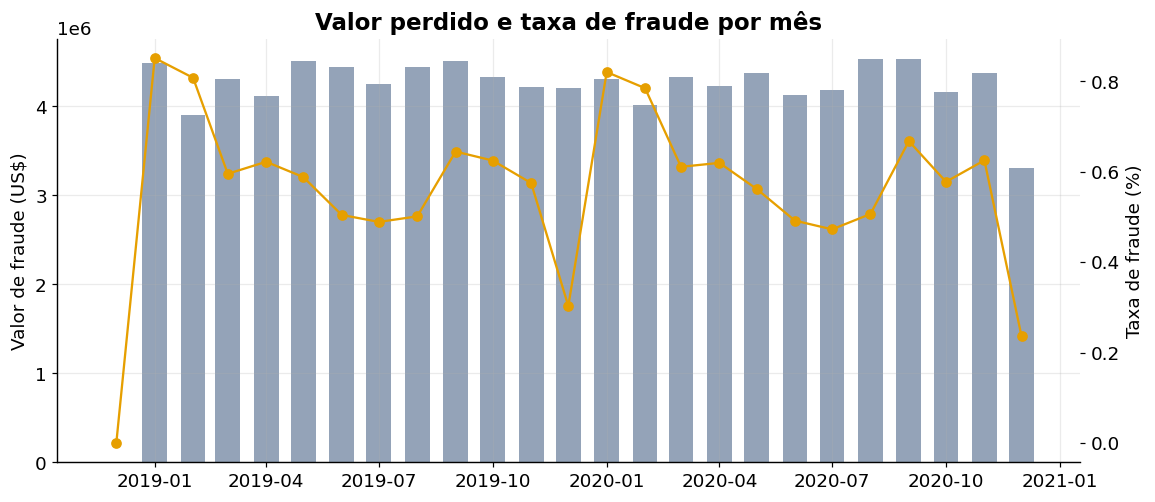

In [22]:
"""Line and bar chart of monthly loss and fraud rate.

Gráfico de barras e linha com perda e taxa de fraude por mês.
"""

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(mensal["mes"].to_list(), mensal["valor_fraude"].to_list(), width=20, color=COR_SECUNDARIA)
ax1.set_ylabel("Valor de fraude (US$)")

# second axis for the rate / segundo eixo para a taxa
ax2 = ax1.twinx()
ax2.plot(mensal["mes"].to_list(), mensal["taxa_pct"].to_list(), color=COR_DESTAQUE, marker="o")
ax2.set_ylabel("Taxa de fraude (%)")
ax2.grid(False)

ax1.set_title("Valor perdido e taxa de fraude por mês")
plt.show()

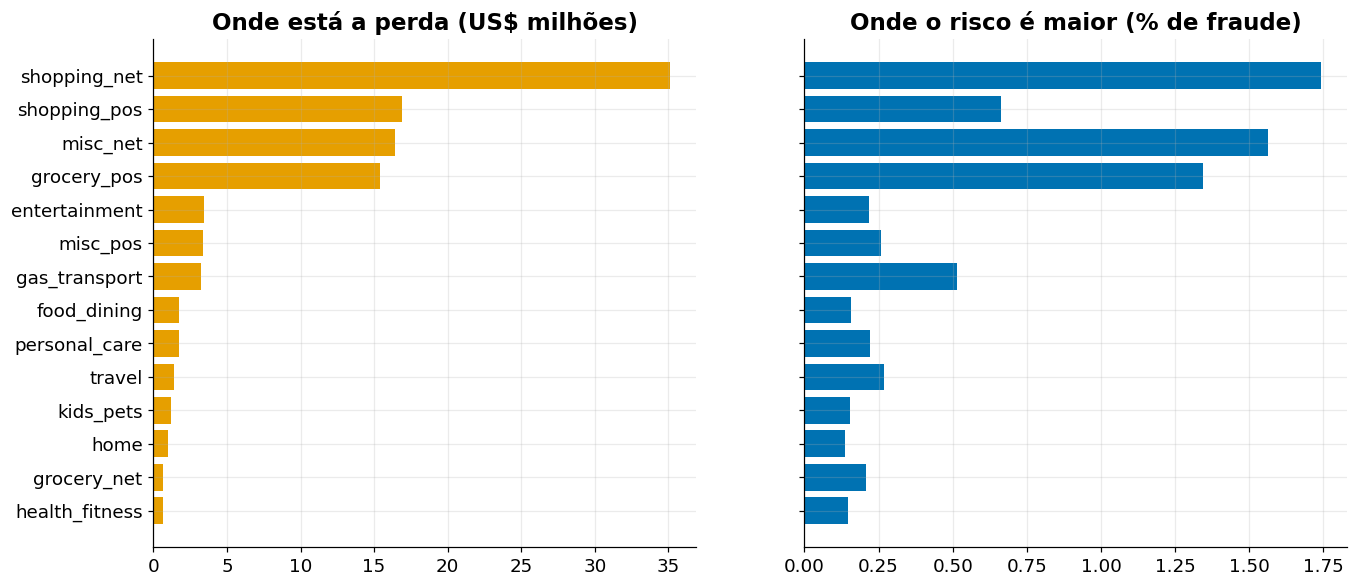

category,n,n_fraudes,valor_fraude,taxa_pct
str,u32,u32,f64,f64
"""health_fitness""",2159052,3197,638932.78,0.148074
"""grocery_net""",1469923,3035,679088.67,0.206473
"""home""",3253637,4434,958149.09,0.136278
"""kids_pets""",3014244,4673,1.1826e6,0.155031
"""travel""",1106289,2952,1.3736e6,0.266838
"""personal_care""",2447892,5387,1.7218e6,0.220067
"""food_dining""",2602138,4057,1.7443e6,0.15591
"""gas_transport""",2980489,15350,3.2335e6,0.515016
"""misc_pos""",2277880,5897,3.3427e6,0.258881


In [23]:
"""Fraud amount and fraud rate by purchase category.

Valor de fraude e taxa de fraude por categoria de compra.
"""

# ascending sort so the largest loss ends up on top of the chart / ordem crescente para a maior perda ficar no topo do gráfico
categorias = (
    lazy.group_by("category")
    .agg(
        pl.len().alias("n"),
        pl.col("is_fraud").sum().alias("n_fraudes"),
        pl.col("amt").filter(pl.col("is_fraud")).sum().alias("valor_fraude"),
    )
    .with_columns((pl.col("n_fraudes") / pl.col("n") * 100).alias("taxa_pct"))
    .sort("valor_fraude")
    .collect()
)

"""Side by side bars: money lost and fraud rate per category.

Barras lado a lado: dinheiro perdido e taxa de fraude por categoria.
"""

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
ax1.barh(categorias["category"].to_list(), (categorias["valor_fraude"] / 1e6).to_list(), color=COR_DESTAQUE)
ax1.set_title("Onde está a perda (US$ milhões)")
ax2.barh(categorias["category"].to_list(), categorias["taxa_pct"].to_list(), color=COR_PRIMARIA)
ax2.set_title("Onde o risco é maior (% de fraude)")
plt.show()

categorias

C:\Users\rafae\AppData\Local\Temp\ipykernel_13932\2095135297.py:11: DeprecationWarning: `cut` is deprecated; use `bin_intervals` instead
  lazy.with_columns(pl.col("amt").cut(quebras, labels=rotulos).cast(pl.String).alias("faixa"))


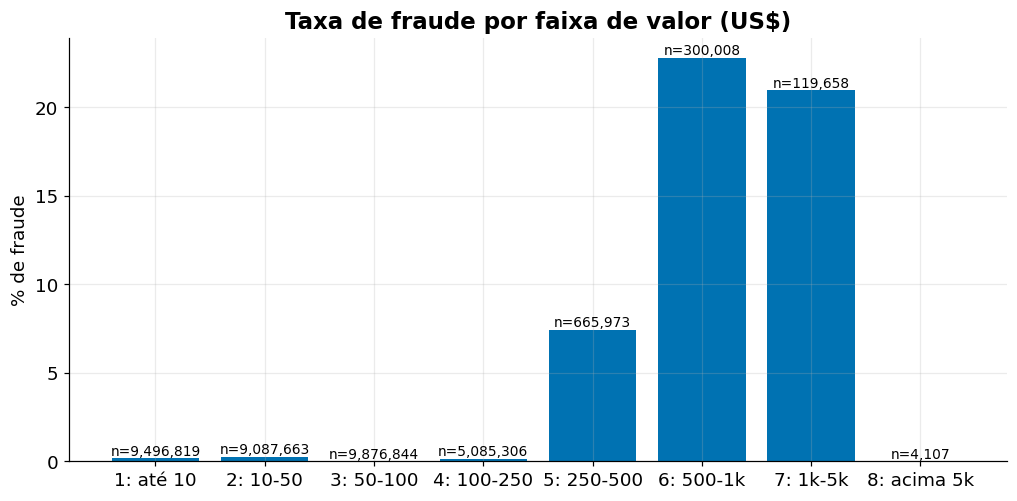

faixa,n,n_fraudes,valor_fraude,taxa_pct
str,u32,u32,f64,f64
"""1: até 10""",9496819,16427,136990.7,0.172974
"""2: 10-50""",9087663,23840,394231.74,0.262334
"""3: 50-100""",9876844,280,21827.16,0.002835
"""4: 100-250""",5085306,6288,1.0260e6,0.12365
"""5: 250-500""",665973,49608,1.5520e7,7.448951
"""6: 500-1k""",300008,68389,5.8126e7,22.795725
"""7: 1k-5k""",119658,25093,2.6949e7,20.9706
"""8: acima 5k""",4107,0,0.0,0.0


In [24]:
"""Fraud rate by purchase amount band.

Taxa de fraude por faixa de valor da compra.
"""

# the number prefix keeps the bands in order when sorted / o prefixo numérico mantém as faixas em ordem ao ordenar
quebras = [10, 50, 100, 250, 500, 1000, 5000]
rotulos = ["1: até 10", "2: 10-50", "3: 50-100", "4: 100-250", "5: 250-500", "6: 500-1k", "7: 1k-5k", "8: acima 5k"]

faixas = (
    lazy.with_columns(pl.col("amt").cut(quebras, labels=rotulos).cast(pl.String).alias("faixa"))
    .group_by("faixa")
    .agg(
        pl.len().alias("n"),
        pl.col("is_fraud").sum().alias("n_fraudes"),
        pl.col("amt").filter(pl.col("is_fraud")).sum().alias("valor_fraude"),
    )
    .with_columns((pl.col("n_fraudes") / pl.col("n") * 100).alias("taxa_pct"))
    .sort("faixa")
    .collect()
)

"""Bar chart of fraud rate by amount band with n above each bar.

Gráfico de barras da taxa de fraude por faixa de valor com n sobre cada barra.
"""

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(faixas["faixa"].to_list(), faixas["taxa_pct"].to_list(), color=COR_PRIMARIA)
ax.bar_label(ax.containers[0], labels=[f"n={v:,}" for v in faixas["n"].to_list()], fontsize=9)
ax.set_title("Taxa de fraude por faixa de valor (US$)")
ax.set_ylabel("% de fraude")
plt.show()

faixas

In [25]:
"""Compare original trans_time with the UTC time built from unix_time.

Compara o trans_time original com o horário UTC criado a partir do unix_time.
"""

teste = pl.read_csv(
    CSV_PATH,
    n_rows=1000,
    columns=["trans_date", "trans_time", "unix_time", "state"],
).with_columns(pl.from_epoch("unix_time", time_unit="s").alias("utc"))
teste.head(8)

trans_date,trans_time,unix_time,state,utc
str,str,i64,str,datetime[μs]
"""2020-02-15""","""02:48:17""",1581715097,"""CA""",2020-02-14 21:18:17
"""2020-02-15""","""01:29:36""",1581710376,"""CA""",2020-02-14 19:59:36
"""2020-02-15""","""11:40:04""",1581747004,"""CA""",2020-02-15 06:10:04
"""2020-02-15""","""01:20:48""",1581709848,"""CA""",2020-02-14 19:50:48
"""2020-02-15""","""01:15:19""",1581709519,"""CA""",2020-02-14 19:45:19
"""2020-02-15""","""06:07:33""",1581727053,"""CA""",2020-02-15 00:37:33
"""2020-02-15""","""02:06:51""",1581712611,"""CA""",2020-02-14 20:36:51
"""2020-02-15""","""03:49:05""",1581718745,"""CA""",2020-02-14 22:19:05


In [26]:
"""Add hour and weekday columns, with an optional offset from UTC.

Adiciona colunas de hora e dia da semana, com ajuste opcional em relação ao UTC.
"""

# hours added to UTC, change only if the time check shows local time / horas somadas ao UTC, altere só se a checagem mostrar horário local
DESLOCAMENTO_HORAS = 0

lazy_t = lazy.with_columns(
    (pl.col("trans_dt") + pl.duration(hours=DESLOCAMENTO_HORAS)).alias("dt_ajustado")
).with_columns(
    pl.col("dt_ajustado").dt.hour().alias("hora"),
    pl.col("dt_ajustado").dt.weekday().alias("dow"),
)
lazy_t.select("trans_dt", "hora", "dow").head(5).collect()

trans_dt,hora,dow
datetime[μs],i8,i8
2020-02-14 21:18:17,21,5
2020-02-14 19:59:36,19,5
2020-02-15 06:10:04,6,6
2020-02-14 19:50:48,19,5
2020-02-14 19:45:19,19,5


In [27]:
"""Fraud rate and volume by hour of day.

Taxa de fraude e volume por hora do dia.
"""

por_hora = (
    lazy_t.group_by("hora")
    .agg(
        pl.len().alias("n"),
        pl.col("is_fraud").sum().alias("n_fraudes"),
    )
    .with_columns((pl.col("n_fraudes") / pl.col("n") * 100).alias("taxa_pct"))
    .sort("hora")
    .collect()
)
por_hora

hora,n,n_fraudes,taxa_pct
i8,u32,u32,f64
0,1110018,1331,0.119908
1,1107899,1353,0.122123
2,1107740,1286,0.116092
3,1110610,1299,0.116963
4,1107826,1352,0.122041
5,1107013,1305,0.117885
6,1435940,1578,0.109893
7,1765303,1814,0.102759
8,1767144,1889,0.106896


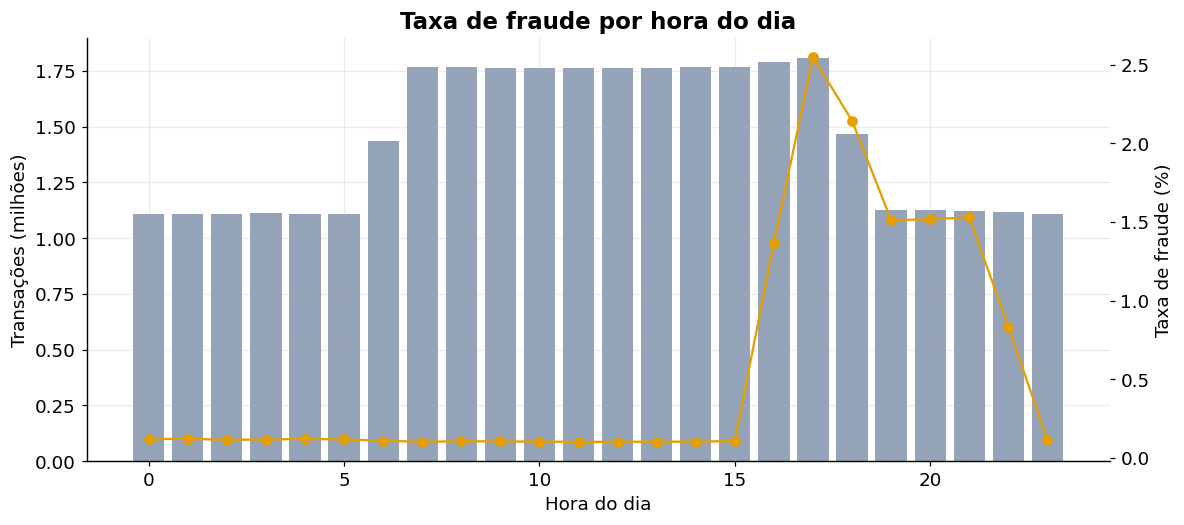

In [28]:
"""Volume bars with the fraud rate line on a second axis.

Barras de volume com a linha da taxa de fraude em um segundo eixo.
"""

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(por_hora["hora"].to_list(), (por_hora["n"] / 1e6).to_list(), color=COR_SECUNDARIA)
ax1.set_xlabel("Hora do dia")
ax1.set_ylabel("Transações (milhões)")

# second axis for the rate / segundo eixo para a taxa
ax2 = ax1.twinx()
ax2.plot(por_hora["hora"].to_list(), por_hora["taxa_pct"].to_list(), color=COR_DESTAQUE, marker="o")
ax2.set_ylabel("Taxa de fraude (%)")
ax2.grid(False)

ax1.set_title("Taxa de fraude por hora do dia")
plt.show()

In [29]:
"""Fraud rate by weekday and hour.

Taxa de fraude por dia da semana e hora.
"""

dow_hora = (
    lazy_t.group_by("dow", "hora")
    .agg(
        pl.len().alias("n"),
        pl.col("is_fraud").sum().alias("n_fraudes"),
    )
    .with_columns((pl.col("n_fraudes") / pl.col("n") * 100).alias("taxa_pct"))
    .sort("dow", "hora")
    .collect()
)

# 7 x 24 matrix, Monday is 1 / matriz 7 x 24, segunda-feira é 1
matriz = np.full((7, 24), np.nan)
for dow, hora, taxa in dow_hora.select("dow", "hora", "taxa_pct").iter_rows():
    matriz[dow - 1, hora] = taxa
dow_hora.select(pl.col("n").min().alias("menor_n"), pl.col("n").max().alias("maior_n"))

menor_n,maior_n
u32,u32
100577,370852


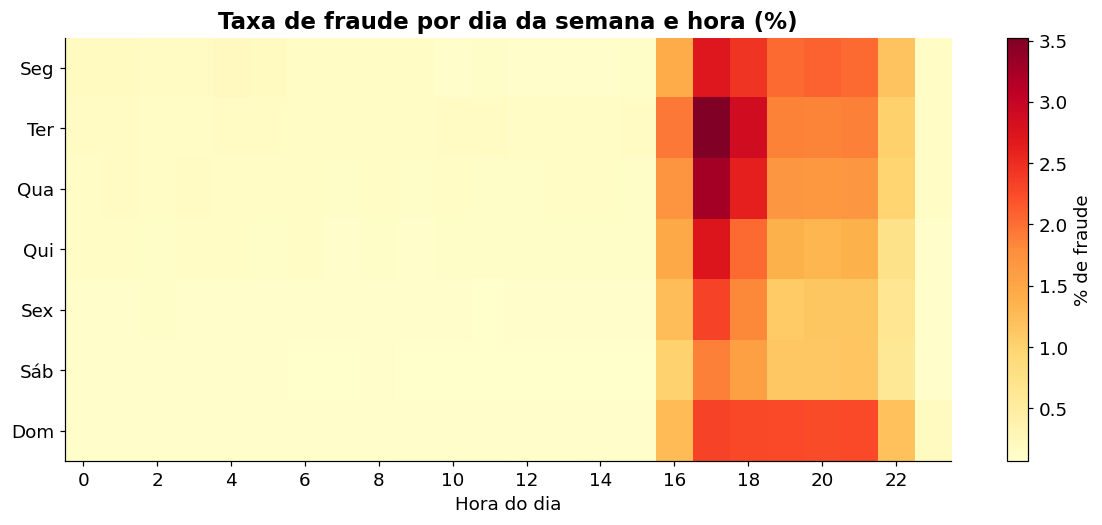

In [30]:
"""Heatmap of fraud rate by weekday and hour.

Mapa de calor da taxa de fraude por dia da semana e hora.
"""

fig, ax = plt.subplots(figsize=(13, 5))
img = ax.imshow(matriz, aspect="auto", cmap="YlOrRd")
ax.set_yticks(range(7), ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"])
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hora do dia")
ax.set_title("Taxa de fraude por dia da semana e hora (%)")
ax.grid(False)
fig.colorbar(img, ax=ax, label="% de fraude")
plt.show()

In [31]:
"""Customer to merchant distance for all frauds and a sample of legit purchases.

Distância cliente-comerciante para todas as fraudes e uma amostra das compras legítimas.
"""

# haversine distance in km / distância haversine em km
lat1, lon1 = pl.col("lat").radians(), pl.col("long").radians()
lat2, lon2 = pl.col("merch_lat").radians(), pl.col("merch_long").radians()
a = ((lat2 - lat1) / 2).sin() ** 2 + lat1.cos() * lat2.cos() * ((lon2 - lon1) / 2).sin() ** 2

# keep every fraud and about 1 percent of legit rows / manter todas as fraudes e cerca de 1 por cento das legítimas
distancias = (
    lazy.filter(pl.col("is_fraud") | (pl.col("unix_time").hash(seed=1) % 100 == 0))
    .select(
        (6371 * 2 * a.sqrt().arcsin()).alias("distancia_km"),
        pl.col("is_fraud"),
    )
    .collect()
)
distancias.group_by("is_fraud").agg(
    pl.len().alias("n"),
    pl.col("distancia_km").median().alias("mediana_km"),
    pl.col("distancia_km").quantile(0.95).alias("p95_km"),
)

is_fraud,n,mediana_km,p95_km
bool,u32,f64,f64
false,345452,78.694555,121.01485
true,189925,78.727515,120.969873


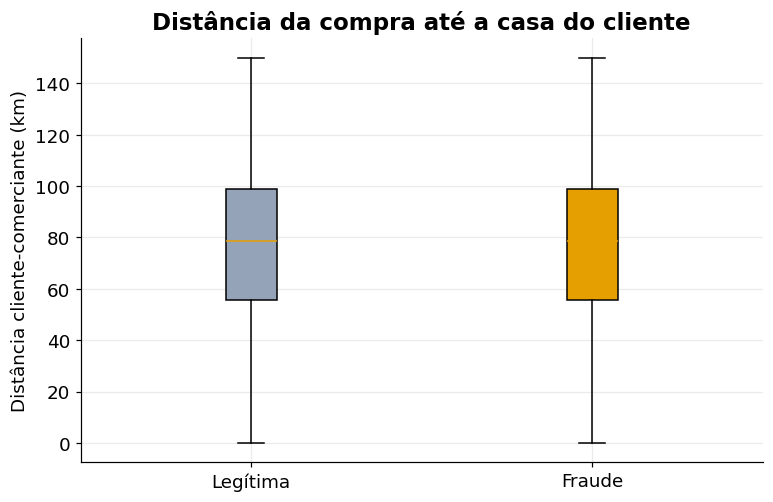

In [32]:
"""Boxplot of distance for legit versus fraud.

Boxplot da distância para legítima versus fraude.
"""

legitima = distancias.filter(~pl.col("is_fraud"))["distancia_km"].to_list()
fraude = distancias.filter(pl.col("is_fraud"))["distancia_km"].to_list()

fig, ax = plt.subplots(figsize=(8, 5))
caixas = ax.boxplot([legitima, fraude], tick_labels=["Legítima", "Fraude"], showfliers=False, patch_artist=True)
for caixa, cor in zip(caixas["boxes"], [COR_SECUNDARIA, COR_DESTAQUE]):
    caixa.set_facecolor(cor)
ax.set_ylabel("Distância cliente-comerciante (km)")
ax.set_title("Distância da compra até a casa do cliente")
plt.show()

In [33]:
"""Fraud amount and fraud rate by state.

Valor de fraude e taxa de fraude por estado.
"""

# minimum transactions per state to trust the rate / mínimo de transações por estado para confiar na taxa
MIN_N = 10_000

estados = (
    lazy.group_by("state")
    .agg(
        pl.len().alias("n"),
        pl.col("is_fraud").sum().alias("n_fraudes"),
        pl.col("amt").filter(pl.col("is_fraud")).sum().alias("valor_fraude"),
    )
    .with_columns((pl.col("n_fraudes") / pl.col("n") * 100).alias("taxa_pct"))
    .collect()
)
print("States below minimum n / Estados abaixo do n mínimo:", estados.filter(pl.col("n") < MIN_N).height)
estados.sort("valor_fraude", descending=True).head(10)

States below minimum n / Estados abaixo do n mínimo: 0


state,n,n_fraudes,valor_fraude,taxa_pct
str,u32,u32,f64,f64
"""CA""",4033120,22285,1.2017e7,0.55255
"""TX""",2660701,14767,8.0387e6,0.555004
"""NY""",2200047,12128,6.5453e6,0.551261
"""FL""",2063959,11619,6.2575e6,0.562947
"""PA""",1509698,8411,4.4907e6,0.557131
"""IL""",1592067,8430,4.4857e6,0.5295
"""OH""",1249875,7000,3.7998e6,0.560056
"""GA""",1142728,6305,3.4295e6,0.55175
"""MI""",1104105,6186,3378450.7,0.560273


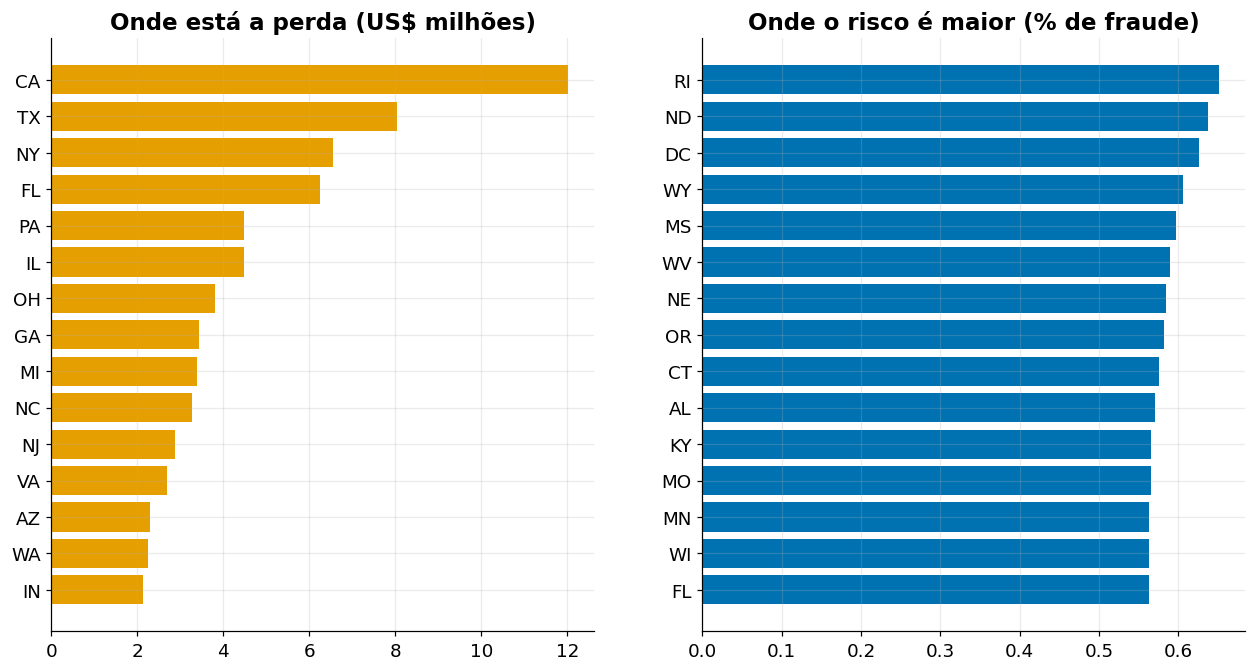

States below minimum n / Estados abaixo do n mínimo: 0


state,n,n_fraudes,valor_fraude,taxa_pct
str,u32,u32,f64,f64
"""CA""",4033120,22285,1.2017e7,0.55255
"""TX""",2660701,14767,8.0387e6,0.555004
"""NY""",2200047,12128,6.5453e6,0.551261
"""FL""",2063959,11619,6.2575e6,0.562947
"""PA""",1509698,8411,4.4907e6,0.557131
"""IL""",1592067,8430,4.4857e6,0.5295
"""OH""",1249875,7000,3.7998e6,0.560056
"""GA""",1142728,6305,3.4295e6,0.55175
"""MI""",1104105,6186,3.3785e6,0.560273


In [34]:
"""Fraud amount and fraud rate by state.

Valor de fraude e taxa de fraude por estado.
"""

# minimum transactions per state to trust the rate / mínimo de transações por estado para confiar na taxa
MIN_N = 10_000

estados = (
    lazy.group_by("state")
    .agg(
        pl.len().alias("n"),
        pl.col("is_fraud").sum().alias("n_fraudes"),
        pl.col("amt").filter(pl.col("is_fraud")).sum().alias("valor_fraude"),
    )
    .with_columns((pl.col("n_fraudes") / pl.col("n") * 100).alias("taxa_pct"))
    .collect()
)

"""Top 15 states by money lost and by fraud rate.

Top 15 estados por dinheiro perdido e por taxa de fraude.
"""

top_valor = estados.sort("valor_fraude", descending=True).head(15).reverse()
top_taxa = estados.filter(pl.col("n") >= MIN_N).sort("taxa_pct", descending=True).head(15).reverse()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))
ax1.barh(top_valor["state"].to_list(), (top_valor["valor_fraude"] / 1e6).to_list(), color=COR_DESTAQUE)
ax1.set_title("Onde está a perda (US$ milhões)")
ax2.barh(top_taxa["state"].to_list(), top_taxa["taxa_pct"].to_list(), color=COR_PRIMARIA)
ax2.set_title("Onde o risco é maior (% de fraude)")
plt.show()

print("States below minimum n / Estados abaixo do n mínimo:", estados.filter(pl.col("n") < MIN_N).height)
estados.sort("valor_fraude", descending=True).head(10)

C:\Users\rafae\AppData\Local\Temp\ipykernel_13932\1199304700.py:12: DeprecationWarning: `cut` is deprecated; use `bin_intervals` instead
  lazy.with_columns(idade.cut(quebras_idade, labels=rotulos_idade).cast(pl.String).alias("faixa_idade"))


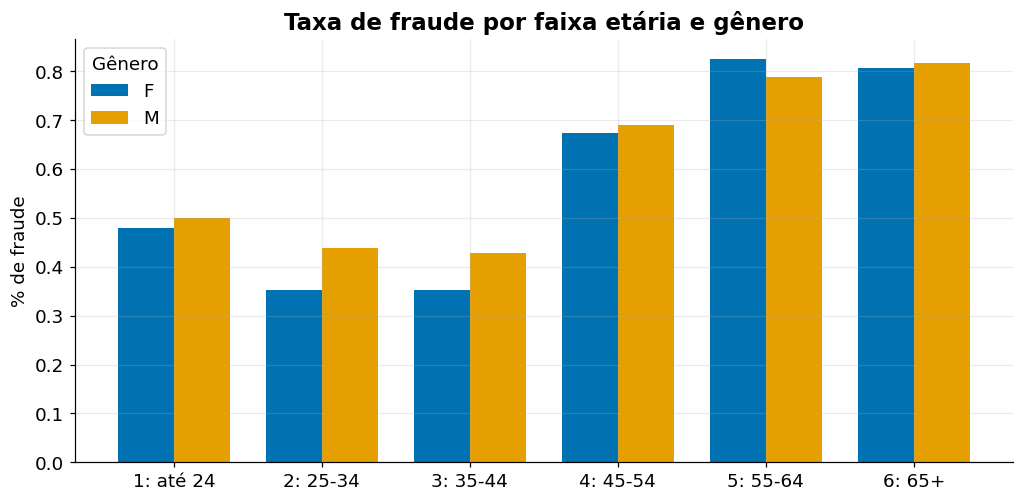

faixa_idade,gender,n,n_fraudes,taxa_pct
str,str,u32,u32,f64
"""1: até 24""","""F""",3137427,15012,0.478481
"""1: até 24""","""M""",3221265,16072,0.498934
"""2: 25-34""","""F""",4063352,14339,0.352886
"""2: 25-34""","""M""",3454973,15159,0.438759
"""3: 35-44""","""F""",3973192,14040,0.353368
"""3: 35-44""","""M""",3706842,15893,0.428748
"""4: 45-54""","""F""",2492716,16797,0.673843
"""4: 45-54""","""M""",2544965,17549,0.689558
"""5: 55-64""","""F""",1884129,15549,0.825262


In [35]:
"""Fraud rate by age band and gender.

Taxa de fraude por faixa etária e gênero.
"""

# age at the purchase date, in years / idade na data da compra, em anos
idade = (pl.col("trans_dt").dt.date() - pl.col("dob").str.to_date()).dt.total_days() / 365.25
quebras_idade = [24, 34, 44, 54, 64]
rotulos_idade = ["1: até 24", "2: 25-34", "3: 35-44", "4: 45-54", "5: 55-64", "6: 65+"]

perfil = (
    lazy.with_columns(idade.cut(quebras_idade, labels=rotulos_idade).cast(pl.String).alias("faixa_idade"))
    .group_by("faixa_idade", "gender")
    .agg(
        pl.len().alias("n"),
        pl.col("is_fraud").sum().alias("n_fraudes"),
    )
    .with_columns((pl.col("n_fraudes") / pl.col("n") * 100).alias("taxa_pct"))
    .sort("faixa_idade", "gender")
    .collect()
)

"""Grouped bars of fraud rate by age band, one bar per gender.

Barras agrupadas da taxa de fraude por faixa etária, uma barra por gênero.
"""

fig, ax = plt.subplots(figsize=(11, 5))
faixas_ordem = sorted(perfil["faixa_idade"].unique().to_list())
largura = 0.38
for i, genero in enumerate(sorted(perfil["gender"].unique().to_list())):
    sub = perfil.filter(pl.col("gender") == genero).sort("faixa_idade")
    posicoes = [faixas_ordem.index(f) + i * largura for f in sub["faixa_idade"].to_list()]
    ax.bar(posicoes, sub["taxa_pct"].to_list(), width=largura, label=genero)
ax.set_xticks([p + largura / 2 for p in range(len(faixas_ordem))], faixas_ordem)
ax.set_ylabel("% de fraude")
ax.set_title("Taxa de fraude por faixa etária e gênero")
ax.legend(title="Gênero")
plt.show()

perfil

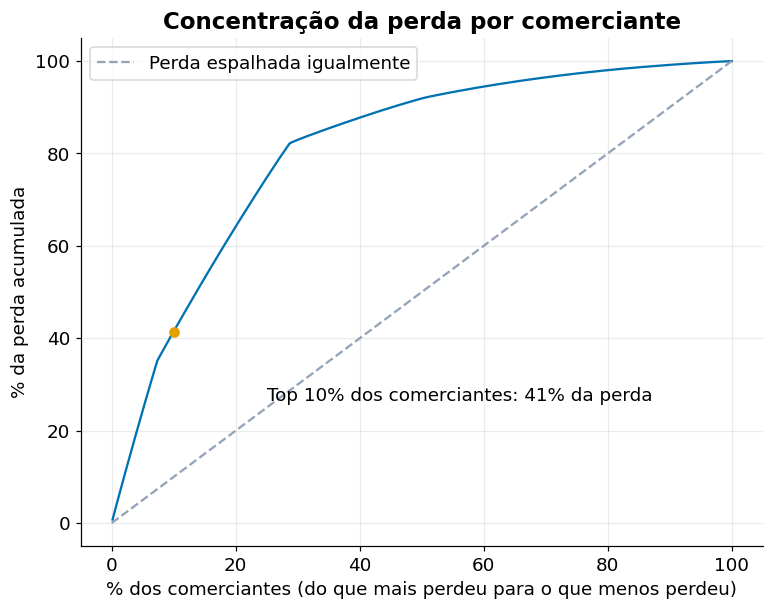

Merchants / Comerciantes: 693


merchant,valor_fraude,perda_acum_pct,comerciantes_pct
str,f64,f64,f64
"""fraud_Goyette Inc""",765159.16,0.748875,0.1443
"""fraud_Jast Ltd""",764724.99,1.497325,0.2886
"""fraud_Schumm PLC""",754493.66,2.235762,0.4329
"""fraud_Kassulke PLC""",747165.21,2.967026,0.577201
"""fraud_Schmidt and Sons""",740423.52,3.691692,0.721501
"""fraud_Ruecker, Beer and Collie…",739441.05,4.415397,0.865801
"""fraud_Baumbach, Feeney and Mor…",737806.83,5.137502,1.010101
"""fraud_Boyer PLC""",735115.25,5.856972,1.154401
"""fraud_Schmeler, Bashirian and …",732331.06,6.573718,1.298701


In [36]:
"""Cumulative share of fraud loss by merchant.

Participação acumulada da perda por fraude por comerciante.
"""

comerciantes = (
    lazy.group_by("merchant")
    .agg(pl.col("amt").filter(pl.col("is_fraud")).sum().alias("valor_fraude"))
    .sort("valor_fraude", descending=True)
    .with_columns(
        (pl.col("valor_fraude").cum_sum() / pl.col("valor_fraude").sum() * 100).alias("perda_acum_pct"),
        ((pl.int_range(1, pl.len() + 1)) / pl.len() * 100).alias("comerciantes_pct"),
    )
    .collect()
)

"""Concentration curve: share of loss versus share of merchants.

Curva de concentração: parcela da perda versus parcela dos comerciantes.
"""

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(comerciantes["comerciantes_pct"].to_list(), comerciantes["perda_acum_pct"].to_list(), color=COR_PRIMARIA)
ax.plot([0, 100], [0, 100], color=COR_SECUNDARIA, linestyle="--", label="Perda espalhada igualmente")

# loss share explained by the top 10 percent of merchants / parcela da perda explicada pelos 10 por cento de comerciantes no topo
top10 = comerciantes.filter(pl.col("comerciantes_pct") <= 10)["perda_acum_pct"].max()
ax.scatter([10], [top10], color=COR_DESTAQUE, zorder=3)
ax.annotate(f"Top 10% dos comerciantes: {top10:.0f}% da perda", (10, top10), xytext=(25, top10 - 15))
ax.set_xlabel("% dos comerciantes (do que mais perdeu para o que menos perdeu)")
ax.set_ylabel("% da perda acumulada")
ax.set_title("Concentração da perda por comerciante")
ax.legend()
plt.show()

print("Merchants / Comerciantes:", comerciantes.height)
comerciantes.head(10)

In [37]:
"""Drop the nearly empty first month before plotting.

Remove o primeiro mês quase vazio antes de plotar.
"""

mensal = mensal.filter(pl.col("n") > 100_000)
mensal.head(3)

mes,n,n_fraudes,valor_fraude,taxa_pct
datetime[μs],u32,u32,f64,f64
2019-01-01 00:00:00,977392,8319,4.4802e6,0.851143
2019-02-01 00:00:00,900704,7273,3.9046e6,0.807479
2019-03-01 00:00:00,1350305,8038,4.3051e6,0.595273


Resultado: o número de fraudes fica estável, em torno de 7 a 8 mil por mês (8.319, 7.273 e 8.038), e o valor perdido também (de 3,9 a 4,5 milhões de dólares). O que muda é o volume de compras, que vai de 977 mil em janeiro para 1,35 milhão em março. Como a taxa é fraudes dividido por compras, ela cai de 0,85% para 0,60% sem que a fraude tenha diminuído. A fraude parece ter um ritmo próprio, que não acompanha a sazonalidade das compras. Isso explica por que a taxa cai em meses de muito movimento, como dezembro, e sobe nos mais fracos, como janeiro. São três meses nesta tabela, então a confirmação está no gráfico dos 24 meses. Os dados mostram essa associação, sem causa comprovada.

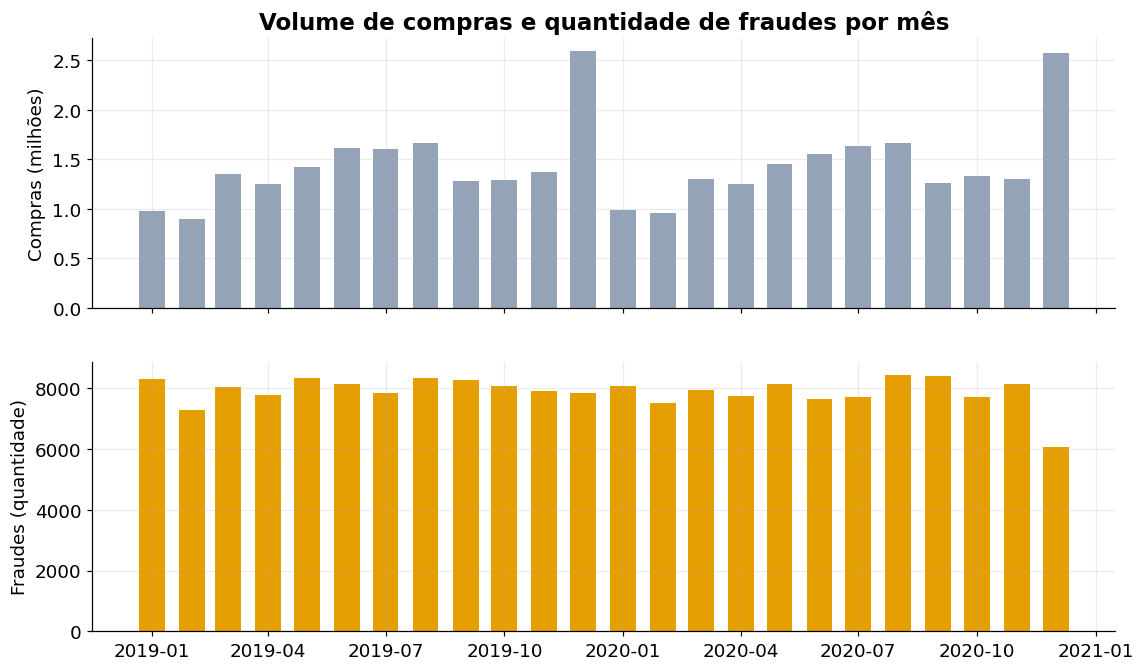

In [38]:
"""Monthly fraud count versus total purchase volume.

Quantidade de fraudes por mês versus volume total de compras.
"""

meses = mensal["mes"].to_list()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax1.bar(meses, (mensal["n"] / 1e6).to_list(), width=20, color=COR_SECUNDARIA)
ax1.set_ylabel("Compras (milhões)")
ax1.set_title("Volume de compras e quantidade de fraudes por mês")

ax2.bar(meses, mensal["n_fraudes"].to_list(), width=20, color=COR_DESTAQUE)
ax2.set_ylabel("Fraudes (quantidade)")
ax2.set_ylim(bottom=0)
plt.show()

Resultado: a quantidade de fraudes é praticamente plana, entre cerca de 7.300 e 8.400 por mês, enquanto o volume de compras varia quase três vezes, de cerca de 0,9 milhão a 2,6 milhões. Em dezembro de 2019 e de 2020 o volume dobra em relação aos meses vizinhos, e as fraudes não acompanham. Por isso a taxa de fraude cai em dezembro (cerca de 0,3% em dezembro de 2019) sem que a fraude tenha diminuído: o que muda é o denominador. Em dezembro de 2020 as fraudes caem para cerca de 6.000, o menor valor da série, mesmo com o maior volume. O mês termina em 30 de dezembro, então é quase completo, mas é um único ponto e não dá para chamar de tendência.

**2. A fraude tem ritmo próprio e não acompanha o volume de compras.** Ocorrem entre 7.300 e 8.400 fraudes por mês durante os 24 meses, enquanto o volume de compras varia de 0,9 a 2,6 milhões. A taxa de fraude cai em dezembro porque o volume dobra, sem que a fraude diminua. Dezembro de 2020 tem o menor número de fraudes da série (cerca de 6.000), mas é um único mês e não indica tendência. Como esse padrão é incomum em dados reais, indica que o dataset é sintético.

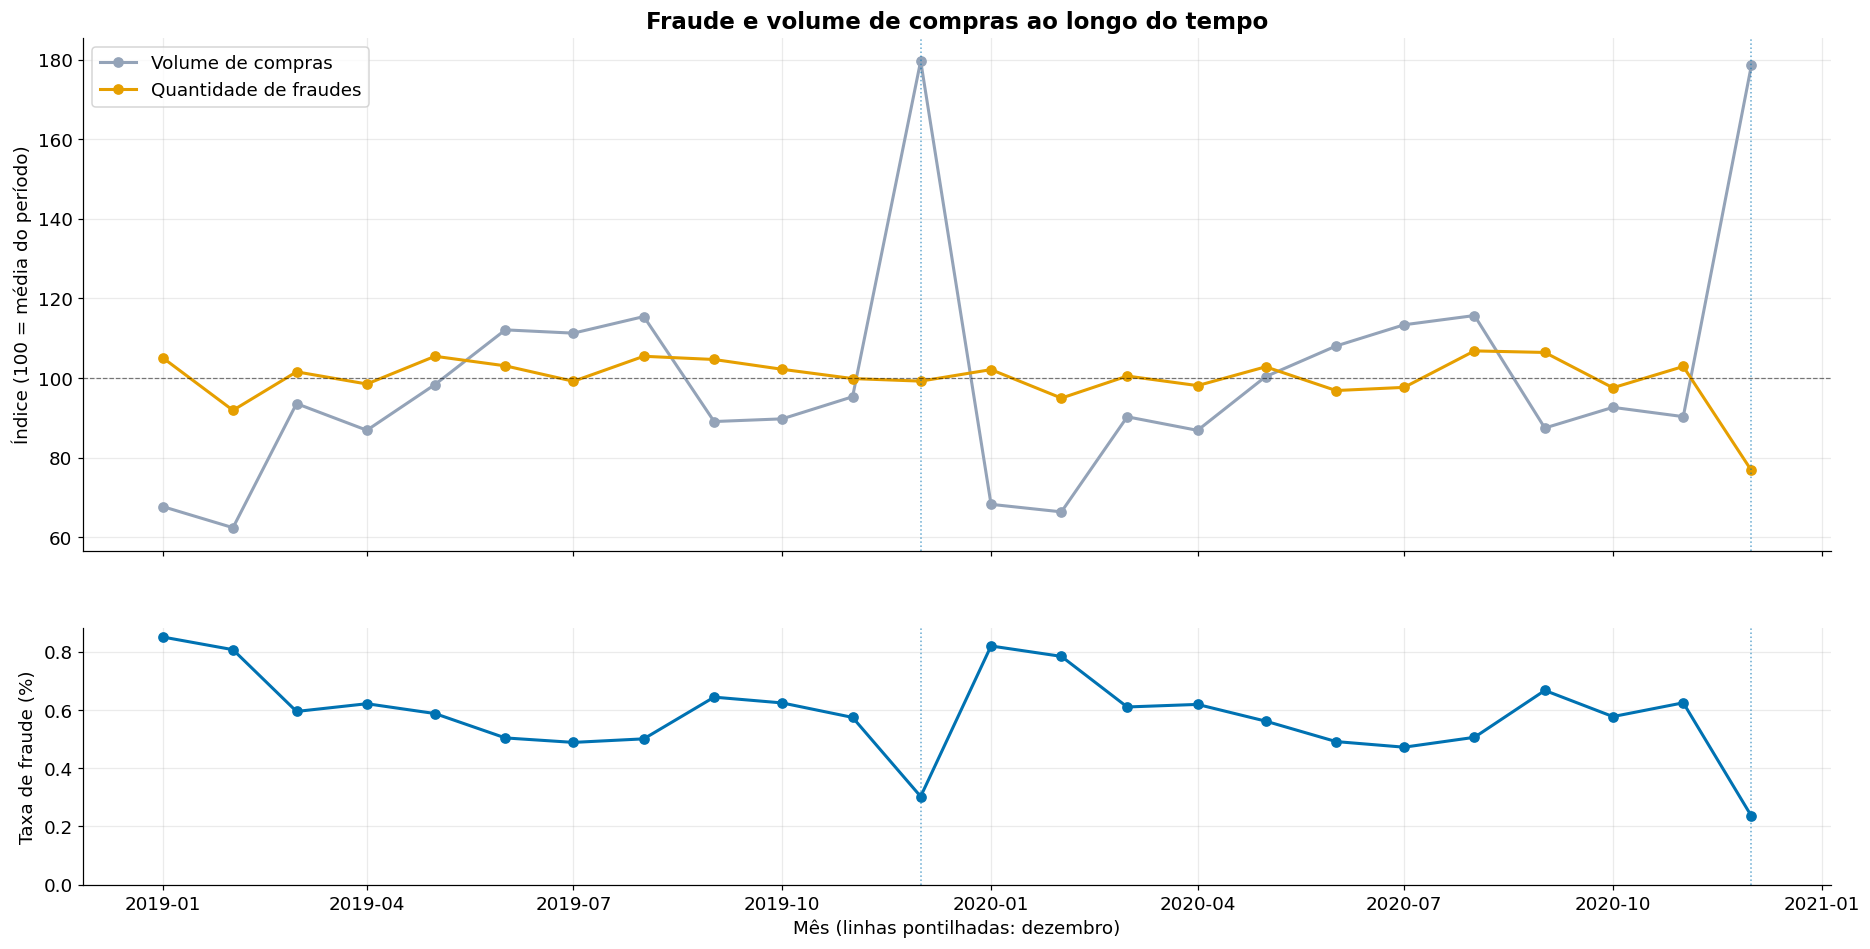

In [39]:
"""Monthly time series of purchase volume, fraud count and fraud rate.

Série temporal mensal de volume de compras, quantidade de fraudes e taxa de fraude.
"""

meses = mensal["mes"].to_list()

# index 100 equals the average of the period / índice 100 equivale à média do período
idx_volume = (mensal["n"] / mensal["n"].mean() * 100).to_list()
idx_fraude = (mensal["n_fraudes"] / mensal["n_fraudes"].mean() * 100).to_list()

# december months to highlight / meses de dezembro para destacar
dezembros = mensal.filter(pl.col("mes").dt.month() == 12)["mes"].to_list()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(20.5, 10), sharex=True, height_ratios=[2, 1])

# top panel: volume versus fraud, both as index / painel de cima: volume versus fraude, ambos em índice
ax1.plot(meses, idx_volume, color=COR_SECUNDARIA, marker="o", linewidth=2, label="Volume de compras")
ax1.plot(meses, idx_fraude, color=COR_DESTAQUE, marker="o", linewidth=2, label="Quantidade de fraudes")
ax1.axhline(100, color="black", linewidth=0.8, linestyle="--", alpha=0.5)
for d in dezembros:
    ax1.axvline(d, color=COR_PRIMARIA, linewidth=1, linestyle=":", alpha=0.6)
ax1.set_ylabel("Índice (100 = média do período)")
ax1.set_title("Fraude e volume de compras ao longo do tempo")
ax1.legend(loc="upper left")

# bottom panel: fraud rate in percent / painel de baixo: taxa de fraude em porcentagem
ax2.plot(meses, mensal["taxa_pct"].to_list(), color=COR_PRIMARIA, marker="o", linewidth=2)
for d in dezembros:
    ax2.axvline(d, color=COR_PRIMARIA, linewidth=1, linestyle=":", alpha=0.6)
ax2.set_ylabel("Taxa de fraude (%)")
ax2.set_ylim(bottom=0)
ax2.set_xlabel("Mês (linhas pontilhadas: dezembro)")
plt.show()

Resultado: o gráfico mostra que o volume e a fraude seguem lógicas diferentes. O volume de compras oscila muito, de 62 a 180 no índice, com picos em dezembro nos dois anos. A quantidade de fraudes fica quase colada na média, entre 92 e 107, e só sai dessa faixa em dezembro de 2020, quando cai para cerca de 77. Como a taxa é fraudes divididas por compras, ela vira um espelho invertido do volume: despenca em dezembro (cerca de 0,3% e 0,24%) e sobe em janeiro (cerca de 0,85% e 0,82%), meses em que o volume é baixo.

Para o negócio, a taxa sozinha engana como indicador. Ela sinalizaria uma melhora em dezembro e uma piora em janeiro, e a fraude em si não mudou nesse intervalo. O acompanhamento deve olhar a quantidade e o valor de fraudes ao lado da taxa. Outro efeito é prático: a carga de revisão do time de fraude tende a ser estável ao longo do ano, perto de 8 mil casos por mês, e não deve ser dimensionada pelo calendário de compras.

O ponto de dezembro de 2020 é o único que foge do padrão, e é só um mês. O dataset vai até o fim do mês, então não parece mês incompleto, mas vale confirmar se a queda vem de algum corte nas últimas semanas, antes de tratá-la como achado.

In [40]:
"""Weekly purchases and frauds from November 2020 to check the December drop.

Compras e fraudes por semana a partir de novembro de 2020 para checar a queda de dezembro.
"""

semanal = (
    lazy.filter(pl.col("trans_dt") >= pl.datetime(2020, 11, 1))
    .group_by(pl.col("trans_dt").dt.truncate("1w").alias("semana"))
    .agg(
        pl.len().alias("n"),
        pl.col("is_fraud").sum().alias("n_fraudes"),
    )
    .with_columns((pl.col("n_fraudes") / pl.col("n") * 100).alias("taxa_pct"))
    .sort("semana")
    .collect()
)
semanal

semana,n,n_fraudes,taxa_pct
datetime[μs],u32,u32,f64
2020-10-26 00:00:00,58658,311,0.530192
2020-11-02 00:00:00,298495,1831,0.613411
2020-11-09 00:00:00,297700,1845,0.619751
2020-11-16 00:00:00,297129,1888,0.635414
2020-11-23 00:00:00,296882,2007,0.676026
2020-11-30 00:00:00,594035,1858,0.312776
2020-12-07 00:00:00,595065,1663,0.279465
2020-12-14 00:00:00,594811,1710,0.287486
2020-12-21 00:00:00,593782,1110,0.186937


**Implicação para o monitoramento:** a taxa de fraude cai em dezembro e sobe em janeiro só porque o volume de compras muda. O acompanhamento deve usar a quantidade e o valor das fraudes, e a taxa deve ser lida junto com o volume.

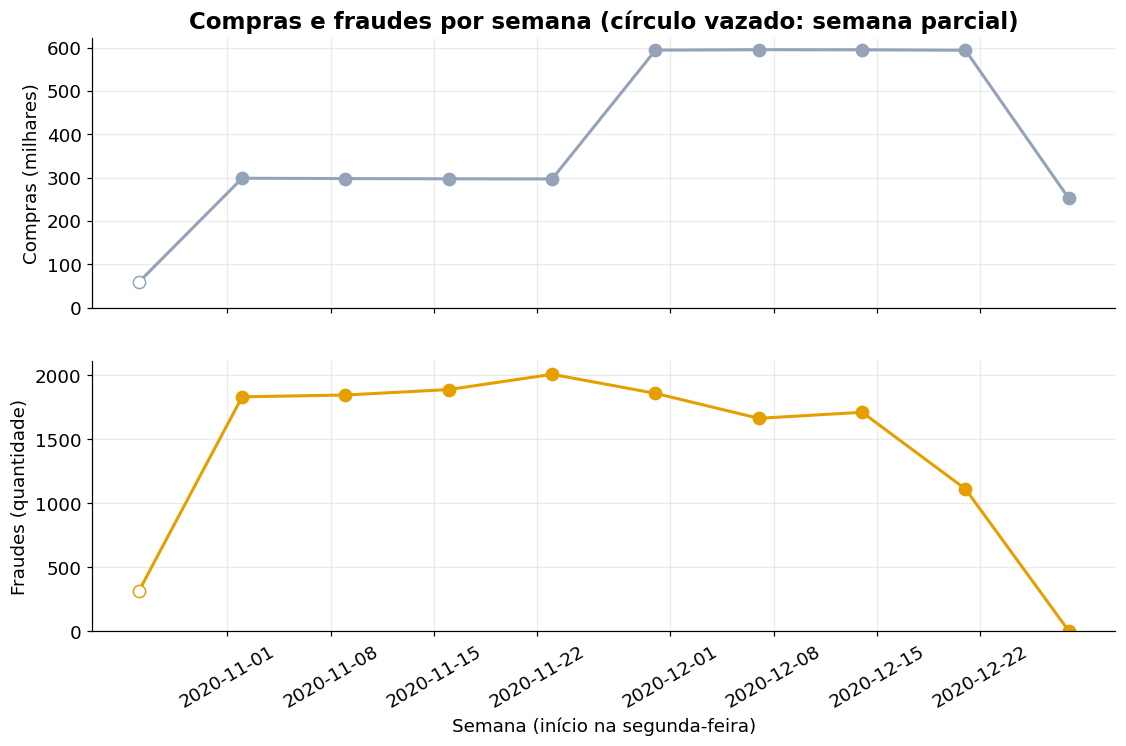

Partial weeks / Semanas parciais: ['2020-10-26']


semana,n,n_fraudes,taxa_pct,parcial
datetime[μs],u32,u32,f64,bool
2020-10-26 00:00:00,58658,311,0.530192,true
2020-11-02 00:00:00,298495,1831,0.613411,false
2020-11-09 00:00:00,297700,1845,0.619751,false
2020-11-16 00:00:00,297129,1888,0.635414,false
2020-11-23 00:00:00,296882,2007,0.676026,false
2020-11-30 00:00:00,594035,1858,0.312776,false
2020-12-07 00:00:00,595065,1663,0.279465,false
2020-12-14 00:00:00,594811,1710,0.287486,false
2020-12-21 00:00:00,593782,1110,0.186937,false


In [41]:
"""Weekly time series of purchases and frauds from November 2020.

Série temporal semanal de compras e fraudes a partir de novembro de 2020.
"""

semanas = semanal["semana"].to_list()

# partial weeks have far fewer purchases than the typical week / semanas parciais têm bem menos compras que a semana típica
parcial = (semanal["n"] < semanal["n"].median() * 0.5).to_list()
semanas_ok = [s for s, p in zip(semanas, parcial) if not p]

"""Weekly time series of purchases and frauds, partial weeks as hollow markers.

Série temporal semanal de compras e fraudes, semanas parciais com marcador vazado.
"""

semanas = semanal["semana"].to_list()

# partial weeks have far fewer purchases than the typical week / semanas parciais têm bem menos compras que a semana típica
parcial = (semanal["n"] < semanal["n"].median() * 0.5).to_list()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
series = [
    (ax1, (semanal["n"] / 1e3).to_list(), COR_SECUNDARIA, "Compras (milhares)"),
    (ax2, semanal["n_fraudes"].to_list(), COR_DESTAQUE, "Fraudes (quantidade)"),
]
for ax, valores, cor, rotulo in series:
    ax.plot(semanas, valores, color=cor, linewidth=2)
    for s, v, p in zip(semanas, valores, parcial):
        ax.plot(s, v, marker="o", color=cor, markerfacecolor="white" if p else cor, markersize=8)
    ax.set_ylabel(rotulo)
    ax.set_ylim(bottom=0)

ax1.set_title("Compras e fraudes por semana (círculo vazado: semana parcial)")
ax2.set_xlabel("Semana (início na segunda-feira)")
ax2.tick_params(axis="x", rotation=30)
plt.show()

print("Partial weeks / Semanas parciais:", [str(s)[:10] for s, p in zip(semanas, parcial) if p])
semanal.with_columns(pl.Series("parcial", parcial))

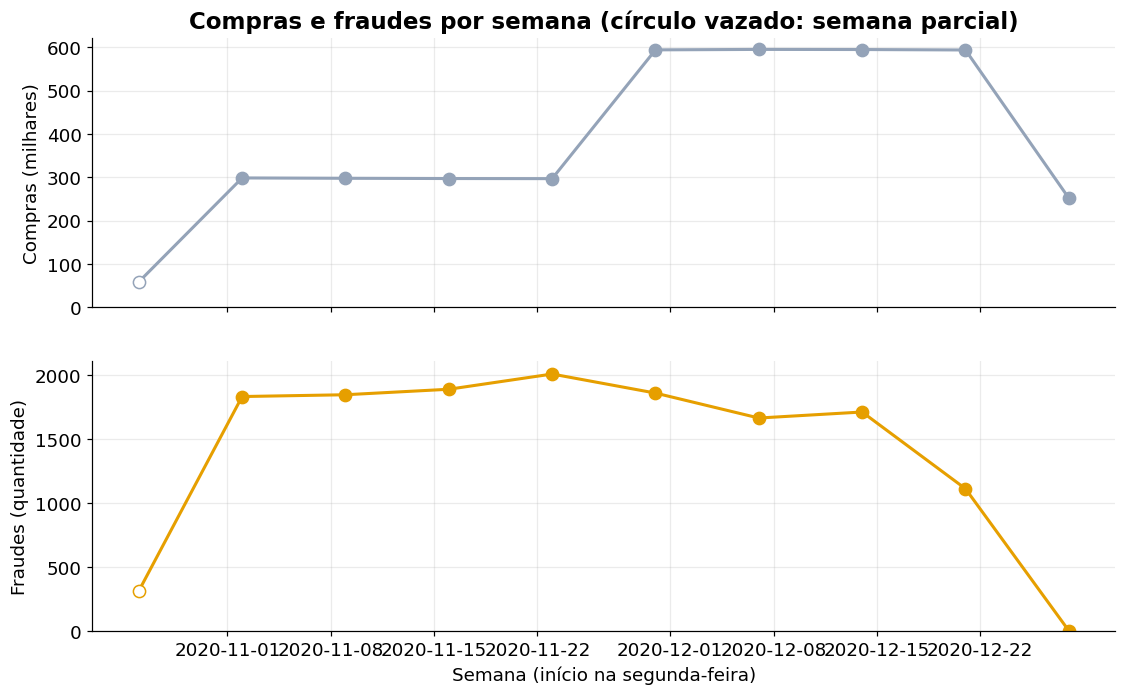

semana,n,n_fraudes,taxa_pct,parcial
datetime[μs],u32,u32,f64,bool
2020-10-26 00:00:00,58658,311,0.530192,true
2020-11-02 00:00:00,298495,1831,0.613411,false
2020-11-09 00:00:00,297700,1845,0.619751,false
2020-11-16 00:00:00,297129,1888,0.635414,false
2020-11-23 00:00:00,296882,2007,0.676026,false
2020-11-30 00:00:00,594035,1858,0.312776,false
2020-12-07 00:00:00,595065,1663,0.279465,false
2020-12-14 00:00:00,594811,1710,0.287486,false
2020-12-21 00:00:00,593782,1110,0.186937,false


In [42]:
"""Weekly time series of purchases and frauds, partial weeks as hollow markers.

Série temporal semanal de compras e fraudes, semanas parciais com marcador vazado.
"""

semanas = semanal["semana"].to_list()

# partial weeks have far fewer purchases than the typical week / semanas parciais têm bem menos compras que a semana típica
parcial = (semanal["n"] < semanal["n"].median() * 0.5).to_list()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
series = [
    (ax1, (semanal["n"] / 1e3).to_list(), COR_SECUNDARIA, "Compras (milhares)"),
    (ax2, semanal["n_fraudes"].to_list(), COR_DESTAQUE, "Fraudes (quantidade)"),
]
for ax, valores, cor, rotulo in series:
    ax.plot(semanas, valores, color=cor, linewidth=2)
    for s, v, p in zip(semanas, valores, parcial):
        ax.plot(s, v, marker="o", color=cor, markerfacecolor="white" if p else cor, markersize=8)
    ax.set_ylabel(rotulo)
    ax.set_ylim(bottom=0)

ax1.set_title("Compras e fraudes por semana (círculo vazado: semana parcial)")
ax2.set_xlabel("Semana (início na segunda-feira)")
plt.show()

semanal.with_columns(pl.Series("parcial", parcial))

Resultado: a checagem mostra que a queda de fraudes em dezembro de 2020 é um efeito de borda do dataset, e não uma melhora real. Nas semanas completas de novembro e começo de dezembro, as fraudes ficam entre cerca de 1.650 e 2.000 por semana. Na semana de 21 de dezembro elas caem para cerca de 1.100, e na última semana (28 a 30 de dezembro) ficam em zero, mesmo com cerca de 250 mil compras registradas. A semana de 21 de dezembro teve volume cheio, de cerca de 595 mil compras, então a queda não vem de menos movimento. Isso indica que as fraudes deixam de ser registradas por volta do dia 24 ou 25 de dezembro, enquanto as compras continuam até o dia 30.

O gráfico também reforça a conclusão 2. O volume dobra de cerca de 300 mil para cerca de 595 mil por semana a partir de 30 de novembro, e as fraudes não acompanham, ficando entre 1.660 e 1.860. Os volumes de novembro são quase idênticos entre as semanas (cerca de 297 mil a 298 mil), o que é outro indício de dado sintético.

In [43]:
"""Daily purchases and frauds for the last days of the dataset.

Compras e fraudes por dia nos últimos dias do dataset.
"""

diario = (
    lazy.filter(pl.col("trans_dt") >= pl.datetime(2020, 12, 15))
    .group_by(pl.col("trans_dt").dt.date().alias("dia"))
    .agg(
        pl.len().alias("n"),
        pl.col("is_fraud").sum().alias("n_fraudes"),
    )
    .sort("dia")
    .collect()
)
diario

dia,n,n_fraudes
date,u32,u32
2020-12-15,61598,242
2020-12-16,68168,255
2020-12-17,69267,240
2020-12-18,101622,239
2020-12-19,122863,263
2020-12-20,116754,266
2020-12-21,54599,204
2020-12-22,61075,321
2020-12-23,68156,288


**2. A fraude tem ritmo próprio e não acompanha o volume de compras.** Ocorrem entre 7.300 e 8.400 fraudes por mês durante os 24 meses, enquanto o volume de compras varia de 0,9 a 2,6 milhões. Nas semanas de dezembro o volume dobra e a quantidade semanal de fraudes continua entre 1.650 e 1.900, então a taxa de fraude cai em dezembro só porque o denominador cresce. A queda de fraudes no fim de dezembro de 2020 é um efeito de borda: as fraudes deixam de ser registradas por volta do dia 25, enquanto as compras seguem até o dia 30. Esse período deve ser excluído das análises e da divisão de treino e teste.

In [44]:
"""Daily time series of purchases and frauds with the last day that has fraud.

Série temporal diária de compras e fraudes com o último dia que tem fraude.
"""

# daily counts from November 1, 2020 / contagem diária a partir de 1º de novembro de 2020
diario = (
    lazy.filter(pl.col("trans_dt") >= pl.datetime(2020, 11, 1))
    .group_by(pl.col("trans_dt").dt.date().alias("dia"))
    .agg(
        pl.len().alias("n"),
        pl.col("is_fraud").sum().alias("n_fraudes"),
    )
    .sort("dia")
    .with_columns(pl.col("n_fraudes").rolling_mean(window_size=7).alias("fraudes_media7d"))
    .collect()
)

# last day with at least one fraud / último dia com pelo menos uma fraude
ultimo_dia_fraude = diario.filter(pl.col("n_fraudes") > 0)["dia"].max()
print("Last day with fraud / Último dia com fraude:", ultimo_dia_fraude)

# full table for the last 15 days, no truncation / tabela completa dos últimos 15 dias, sem cortes
pl.Config.set_tbl_rows(20)
diario.tail(15)

Last day with fraud / Último dia com fraude: 2020-12-25


dia,n,n_fraudes,fraudes_media7d
date,u32,u32,f64
2020-12-17,69267,240,247.0
2020-12-18,101622,239,246.285714
2020-12-19,122863,263,246.428571
2020-12-20,116754,266,244.285714
2020-12-21,54599,204,244.142857
2020-12-22,61075,321,255.428571
2020-12-23,68156,288,260.142857
2020-12-24,68785,148,247.0
2020-12-25,101784,149,234.142857


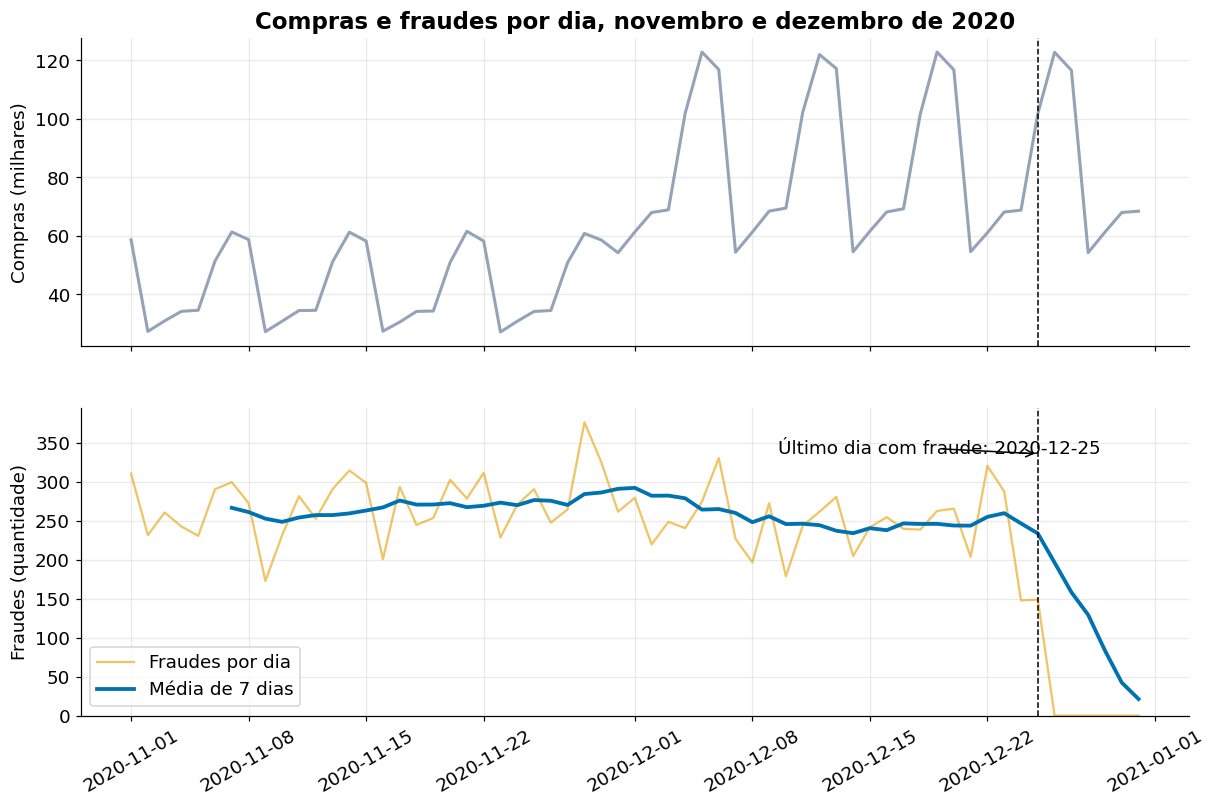

In [45]:
"""Two panel daily chart: purchases and frauds with a 7 day average.

Gráfico diário em dois painéis: compras e fraudes com média de 7 dias.
"""

dias = diario["dia"].to_list()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

# top panel: purchases per day / painel de cima: compras por dia
ax1.plot(dias, (diario["n"] / 1e3).to_list(), color=COR_SECUNDARIA, linewidth=2)
ax1.set_ylabel("Compras (milhares)")
ax1.set_title("Compras e fraudes por dia, novembro e dezembro de 2020")

# bottom panel: frauds per day and 7 day average / painel de baixo: fraudes por dia e média de 7 dias
ax2.plot(dias, diario["n_fraudes"].to_list(), color=COR_DESTAQUE, linewidth=1.5, alpha=0.6, label="Fraudes por dia")
ax2.plot(dias, diario["fraudes_media7d"].to_list(), color=COR_PRIMARIA, linewidth=2.5, label="Média de 7 dias")
ax2.set_ylabel("Fraudes (quantidade)")
ax2.set_ylim(bottom=0)
ax2.legend(loc="lower left")

# mark the last day with fraud in both panels / marcar o último dia com fraude nos dois painéis
for ax in (ax1, ax2):
    ax.axvline(ultimo_dia_fraude, color="black", linestyle="--", linewidth=1)
ax2.annotate(
    f"Último dia com fraude: {ultimo_dia_fraude}",
    (ultimo_dia_fraude, ax2.get_ylim()[1] * 0.85),
    xytext=(-170, 0),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"},
)
ax2.tick_params(axis="x", rotation=30)
plt.show()

Resultado: os dados são cortados em degrau, não em queda gradual. Até 23 de dezembro a média de 7 dias fica entre cerca de 235 e 295 fraudes por dia. Em 24 e 25 de dezembro caem para cerca de metade (perto de 150 por dia) e, a partir de 26 de dezembro, ficam em zero, enquanto as compras seguem normais, com mais de 115 mil por dia no fim de semana de 26 e 27. O último dia com fraude é 25/12/2020, valor impresso pelo código. Atraso na confirmação de fraude apareceria como uma rampa de vários dias, e não como um degrau. Por isso os rótulos a partir de 24 de dezembro estão incompletos e o corte vem do próprio dataset. Os valores diários acima foram lidos no gráfico, então são aproximados.

O gráfico traz outro achado. Em novembro as compras vão de cerca de 27 mil nas segundas a cerca de 60 mil nos fins de semana, com o mesmo desenho toda semana, e em dezembro o ciclo inteiro dobra de tamanho. As fraudes não têm ciclo semanal visível e ficam em torno de 250 por dia em qualquer dia. Isso reforça a conclusão 2 em escala diária, e o ciclo idêntico toda semana é mais um indício de dado sintético.

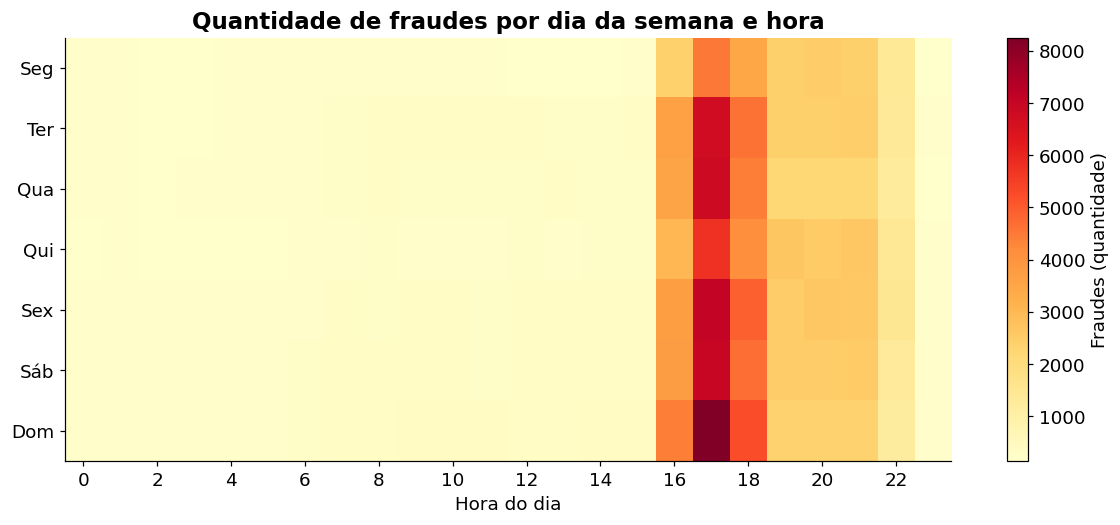

In [46]:
"""Apply the cutoff date so days with incomplete fraud labels are excluded.

Aplica a data de corte para excluir os dias com rótulos de fraude incompletos.
"""

# first day with incomplete fraud labels, from the daily chart / primeiro dia com rótulos de fraude incompletos, pelo gráfico diário
DATA_CORTE = pl.datetime(2020, 12, 24)

# keep a handle on the full data and filter / guardar o ponteiro da base completa e filtrar
lazy_completo = lazy
lazy = lazy.filter(pl.col("trans_dt") < DATA_CORTE)

# effect of the cutoff on volume and fraud rate / efeito do corte no volume e na taxa de fraude
pl.concat([
    lazy_completo.select(pl.len().alias("n"), pl.col("is_fraud").sum().alias("n_fraudes")).with_columns(pl.lit("antes").alias("base")),
    lazy.select(pl.len().alias("n"), pl.col("is_fraud").sum().alias("n_fraudes")).with_columns(pl.lit("depois").alias("base")),
]).with_columns((pl.col("n_fraudes") / pl.col("n") * 100).alias("taxa_pct")).collect()

"""Heatmap of fraud count by weekday and hour, to compare with the rate map.

Mapa de calor da quantidade de fraudes por dia da semana e hora, para comparar com o mapa da taxa.
"""

# 7 x 24 matrix of fraud counts, Monday is 1 / matriz 7 x 24 de quantidade de fraudes, segunda-feira é 1
matriz_qtd = np.full((7, 24), np.nan)
for dow, hora, n_fraudes in dow_hora.select("dow", "hora", "n_fraudes").iter_rows():
    matriz_qtd[dow - 1, hora] = n_fraudes

fig, ax = plt.subplots(figsize=(13, 5))
img = ax.imshow(matriz_qtd, aspect="auto", cmap="YlOrRd")
ax.set_yticks(range(7), ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"])
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hora do dia")
ax.set_title("Quantidade de fraudes por dia da semana e hora")
ax.grid(False)
fig.colorbar(img, ax=ax, label="Fraudes (quantidade)")
plt.show()

**2. A fraude tem ritmo próprio e não acompanha o volume de compras.** Ocorrem entre 7.300 e 8.400 fraudes por mês, e perto de 250 por dia, sem ciclo semanal visível, enquanto as compras vão de cerca de 27 mil nas segundas a cerca de 60 mil nos fins de semana em novembro e dobram em dezembro. A taxa de fraude cai em dezembro só porque o volume cresce. As fraudes deixam de ser registradas em 25/12/2020, com queda em degrau, e as compras seguem até 31/12. A análise e os modelos usam os dados até 23/12/2020.

# **Part 7 - Conclusão final**

# **Conclusão final: onde está a perda por fraude**

Base analisada: 34,6 milhões de transações de janeiro de 2019 a dezembro de 2020, das quais cerca de 190 mil são fraude (0,55%). A perda soma perto de 100 milhões de dólares. As fraudes só estão registradas até 25/12/2020, então a análise considera os dados até 23/12/2020.

## Onde está a perda

- **A fraude é rara em quantidade, mas pesa em dinheiro.** São 0,55% das transações e 4,15% do valor movimentado, então a fraude tem ticket médio cerca de 7,5 vezes o ticket geral.
- **Quatro categorias concentram cerca de 80% da perda:** shopping_net, shopping_pos, misc_net e grocery_pos.
- **Perda e risco não coincidem.** O maior risco está em shopping_net (1,7%), misc_net (1,6%) e grocery_pos (1,3%). A shopping_pos é a segunda em perda, mas tem risco de 0,7%, então o dinheiro perdido ali vem do volume de compras e não de uma chance maior de fraude.
- **O valor da compra é o sinal mais forte.** Abaixo de 250 dólares a taxa é próxima de zero. Entre 250 e 500 ela é de cerca de 7%, entre 500 e 1.000 de cerca de 23% e entre 1.000 e 5.000 de cerca de 21%. Essas três faixas reúnem 3% das transações e cerca de três quartos das fraudes.
- **A perda está concentrada em poucos comerciantes.** Entre 693 comerciantes, os 10% do topo respondem por 41% da perda e cerca de 28% deles respondem por 82%.

## Quando e com quem

- **A fraude tem ritmo próprio e não acompanha o volume de compras.** São de 7.300 a 8.400 fraudes por mês, e perto de 250 por dia, enquanto o volume de compras varia de 0,9 a 2,6 milhões por mês e dobra em dezembro. A taxa de fraude cai em dezembro e sobe em janeiro só porque o denominador muda.
- **Existe uma janela de risco no fim do dia.** A taxa fica perto de 0,1% da hora 0 à hora 15, chega a cerca de 2,5% na hora 17 e volta a 0,1% na hora 23. Esse padrão não vem do volume, porque das horas 19 a 22 há menos compras que de dia e a taxa segue alta. As horas estão em UTC e ainda faltam confirmar contra o horário original.
- **Clientes de 45 anos ou mais têm taxa cerca de duas vezes maior** (0,7% a 0,8%, contra 0,35% a 0,44% entre 25 e 44 anos). A diferença entre gêneros é menor que 0,1 ponto percentual. A idade pode refletir o perfil de compra e não ser o fator em si.
- **A distância entre cliente e comerciante não separa fraude de compra legítima.** A mediana é de cerca de 79 km nos dois grupos.

## O que levar para os modelos

- **Manter:** valor da compra, hora, categoria e idade.
- **Criar:** indicador da faixa de 250 a 5.000 dólares e indicador da janela de risco, depois de confirmar o fuso.
- **Descartar:** latitudes e longitudes brutas, que têm correlação de 0,99 a 1,00 entre cliente e comerciante, e uma das duas colunas de gênero.
- **Testar, sem esperar ganho:** `distancia_km`, que não tem sinal sozinha.
- **Não confiar na correlação simples.** A hora tem correlação de só 0,06 com a fraude, mesmo com a janela de risco de 25 vezes, porque o padrão é um pico e não uma linha reta. Para esses padrões, o gráfico por faixa é mais informativo que o mapa de correlação.
- **Dividir treino e teste no tempo, até 23/12/2020.** Depois dessa data as compras seguem, mas as fraudes não estão registradas, e o teste ficaria com rótulos incompletos.

## Recomendação para o time de fraude

1. **Priorizar a revisão por valor.** Revisar toda compra entre 250 e 5.000 dólares cobriria cerca de 75% das fraudes, mas com precisão de apenas cerca de 13%: a cada 8 compras revisadas, só uma é fraude. A regra por valor serve para priorizar a fila, e o modelo deve refinar quais dessas compras revisar primeiro.
2. **Monitorar quantidade e valor de fraudes, e usar a taxa só junto com o volume.** A taxa sozinha sinalizaria melhora em dezembro e piora em janeiro, sem que a fraude tenha mudado.
3. **Dimensionar a equipe pela carga estável, perto de 8 mil casos por mês, e não pelo calendário de compras.**
4. **Acompanhar os comerciantes do topo da curva de concentração,** que reúnem a maior parte da perda.
5. **Não investir em regras de distância.** Neste dataset ela não distingue fraude de compra legítima.

## Limitações dos dados

- **O dataset é sintético, com sinais claros:** nenhuma fraude acima de cerca de 1.250 dólares, distância sempre abaixo de 150 km, clientes de 16 e 17 anos com cartão, ciclo semanal de compras idêntico em novembro e fraude constante independente do volume. Em dados reais, os padrões tendem a ser menos nítidos, e os números aqui não devem ser tratados como estimativa do mundo real.
- **As fraudes só estão registradas até 25/12/2020.**
- **Os dados mostram associação, não causa.** As conclusões apontam onde olhar, e não explicam por que a fraude acontece.